# Restored convection discovery notebook

The scientific workflow is restored from `102c126`, before the batch refactor.
Original data preparation, JAX filtering, time scaling, library, homogeneous AIC/jump searches, and general tau/phi discovery are retained. The six trailing inhomogeneous experiments are consolidated into one settings table with their original targets and initializers. Plots are at the end. Runtime overrides and result archiving do not retarget regressions.

The original scientific quirks are intentionally retained: dt=(t_last-t_first)/Nt, the recovery time-scale factor 10, edge-padded filtering/trimming fallback, fixed 50-point crop, and the original broad library including w. This restoration does not silently apply the TODO fixes.

See PACE_FILTER_SWEEP.md for execution controls and the restoration record.


In [12]:
import joblib
import h5py
import numpy as np
from SPIDER.commons.utils import save, load
from SPIDER.continuous.library import *
import gc
from SPIDER.continuous.process_library_terms import *
from SPIDER.commons.identify_models import *
from SPIDER.commons.sparse_reg_bf import AIC, Initializer, ModelIterator, Residual, Scaler, Threshold, sparse_reg_bf
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
#import xarray 
#import xarray as xr
import dataclasses
import time
jax.config.update("jax_enable_x64", True)
import numpy as np
import os, joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from numpy.polynomial.chebyshev import chebvander

import contextlib
import joblib
from tqdm import tqdm

@contextlib.contextmanager
def tqdm_joblib(tqdm_object):
    """Context manager to patch joblib to report into tqdm progress bar given as argument"""
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_batch_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_batch_callback
        tqdm_object.close()

In [13]:
# Execution/output controls only. Scientific defaults remain in the original cells.
import json
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy

run_controls = dict(globals().get('RUN_CONFIG', {}))
RUN_BASELINE_RESIDUALS = bool(run_controls.get('baseline_residuals', True))
analysis_run_dir = Path(run_controls.get('run_dir') or
    (Path('thesis_runs') / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S.%fZ')+'_'+uuid4().hex[:8])))
analysis_run_dir.mkdir(parents=True, exist_ok=True)
homogeneous_history = []
legacy_regression_failures = []

def restored_json_value(value):
    if isinstance(value, np.ndarray):
        return restored_json_value(value.tolist())
    if isinstance(value, np.generic):
        return restored_json_value(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return {'nonfinite': str(value)}
    if isinstance(value, dict):
        return {str(key): restored_json_value(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [restored_json_value(item) for item in value]
    return value

def restored_write_report(name, value):
    (analysis_run_dir / name).write_text(json.dumps(restored_json_value(value),
        indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')

def restored_equation_record(equation):
    return dict(equation=str(equation), rank=equation.rank,
        coefficients=[dict(term=str(term), coefficient=float(c))
                      for term, c in zip(equation.terms, equation.coeffs)])

def restored_regression_record(result):
    return {name: getattr(result, name, None) for name in
        ('xi', 'lambd', 'lambda1', 'best_term', 'lambda_test', 'lambda1_test',
         'all_xis', 'all_lambdas', 'all_lambdas_test')}

def record_homogeneous_run(label, settings, equations, errors, results, derived, excluded):
    record = dict(label=label, settings=settings,
        equations=[dict(**restored_equation_record(eq), acceptance_error=float(error))
                   for eq, error in zip(equations, errors)],
        regression_results=[restored_regression_record(result) for result in results],
        derived={str(irrep): {str(parent): [restored_equation_record(eq) for eq in children]
                 for parent, children in entries.items()} for irrep, entries in derived.items()},
        excluded={str(irrep): sorted(map(str, entries)) for irrep, entries in excluded.items()})
    homogeneous_history.append(record)
    restored_write_report('homogeneous_recovery.json', dict(runs=homogeneous_history,
        failures=legacy_regression_failures,
        validation='original random weak-row train/test splits; no independent trajectory validation'))


In [14]:
# --- NEW CELL (Call this 'Cell 2 - New') ---
# Run this cell INSTEAD of the old cells 2, 3, and 4.

print("Loading preprocessed arrays from .npz file...")

# Path to the file you just saved
load_path = run_controls.get('data_path', '/storage/scratch1/2/ashelestov3/preprocessed_paper_data.npz')

# Load the data from the .npz file
data = np.load(load_path)
print("loaded - processing")
# Re-create your variables from the saved data
V = data['U']
U = data['V']
P = data['P']
B = data['B']
W = data['W']
x = data['x']
y = data['y']
t = data['t']
# An explicit batch time window is optional; default is the original full data.
if run_controls.get('time_start', 0) != 0 or run_controls.get('time_stop') is not None:
    run_time_slice = slice(run_controls.get('time_start', 0), run_controls.get('time_stop'))
    U, V, P, B, W = [a[..., run_time_slice] for a in (U, V, P, B, W)]
    t = t[run_time_slice]
print(y,y[1]-y[0],y[201]-y[200])
y=np.linspace(0,1,num=1536)

print(y,y[1]-y[0],y[201]-y[200])
del(data)
# IMPORTANT: You must also re-define the parameters from your old Cell 3,
# as the rest of your notebook depends on them.
size_x = 4096
size_y = 1536
inner_steps = 1
outer_steps = t.shape[0]

Lx =  4
Ly = 1
Nx = size_x
Ny = size_y
Nt = outer_steps
# Calculate dx/dy from the actual new coordinate arrays
dx = x[1] - x[0]
dy = y[1] - y[0]
print(f"Updated dx: {dx}, dy: {dy}")
Lt = t[-1]-t[0]
dt = Lt/Nt
Rayleigh = 1e8
Prandtl = 1
kappa = (Rayleigh * Prandtl)**(-1/2)
print("Done loading!")
print("U shape:", U.shape)
print("P shape:", P.shape)
print("dx:", dx)
print("dt:", dt)
print(dy-Ly / (Ny - 1))

Loading preprocessed arrays from .npz file...
loaded - processing
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
Updated dx: 0.0009765625, dy: 0.0006514657980456026
Done loading!
U shape: (4096, 1536, 101)
P shape: (4096, 1536, 101)
dx: 0.0009765625
dt: 2.380099009900647e-05
0.0


In [15]:
import builtins
import jax
import jax.numpy as jnp
from functools import partial

# --- REPLACEMENT FILTERING FUNCTIONS (Adapted for 2D: x, y) ---

def _sigma_from_delta(delta):
    return delta / jnp.sqrt(12.0)

def _trap_weights_nonuniform(x):
    dx = jnp.diff(x)
    w_mid = 0.5 * (dx[:-1] + dx[1:])
    w0 = 0.5 * dx[0]
    wn = 0.5 * dx[-1]
    return jnp.concatenate([jnp.array([w0]), w_mid, jnp.array([wn])])

@partial(jax.jit, static_argnums=(4,))
def _convolve1d_nonuniform_gaussian(arr, coord, delta, alpha, axis):
    sigma = _sigma_from_delta(delta)
    R = alpha * delta
    n = coord.size

    # Trapezoidal weights
    wq = _trap_weights_nonuniform(coord)

    # Move axis to front for easy processing
    a = jnp.moveaxis(arr, axis, 0)  # shape: (n, ...)

    # Build the pairwise distance matrix (n, n)
    dists = coord[:, None] - coord[None, :]
    kernel = jnp.exp(-0.5 * (dists / sigma)**2)
    mask = jnp.abs(dists) <= R
    kernel = kernel * mask

    # Weighted kernel
    weighted_kernel = kernel * wq[None, :]  # shape (n, n)
    norm = weighted_kernel.sum(axis=1, keepdims=True)
    weights = weighted_kernel / norm  # normalize rows

    # Apply weights: shape (n, ...) = (n, n) @ (n, ...)
    out = jnp.tensordot(weights, a, axes=(1, 0))  # shape (n, ...)

    return jnp.moveaxis(out, 0, axis)

def trim_edges_jax(array, x=None, y=None, delta=0.0):
    """
    Trims `delta` distance from the edges of a JAX array and coordinates.
    Adapted for 2D inputs (x, y).
    """
    def get_valid_indices(coord):
        return jnp.where((coord >= coord[0] + delta) & (coord <= coord[-1] - delta))[0]

    slices = []
    new_coords = []

    # Iterate over x and y only (matching array shape order)
    for coord in (x, y):
        if coord is not None:
            idx = get_valid_indices(coord)
            if len(idx) > 0:
                start = int(idx[0])
                end = int(idx[-1]) + 1
                slices.append(builtins.slice(start, end))
                new_coords.append(coord[start:end])
            else:
                # Fallback if delta trims everything
                slices.append(builtins.slice(None))
                new_coords.append(coord)
        else:
            slices.append(builtins.slice(None))
            new_coords.append(None)

    # Trim array using tuple of slices
    # The array has a time dimension at the end, keep it full
    slices.append(builtins.slice(None)) 
    trimmed_array = array[tuple(slices)]

    return trimmed_array, *new_coords

def gaussian_filter_2d_finite_support_over_time(field, x, y, delta, alpha):
    """
    Applies Gaussian filter along x, y axes at each time slice.
    field: (Nx, Ny, Nt)
    """
    print(field.shape)
    dx = float(x[1] - x[0])
    dy = float(y[1] - y[0])
    
    # ADDED: Pre-calculate constant kernels
    kernel_x = _get_uniform_gaussian_kernel(dx, delta, alpha)
    kernel_y = _get_uniform_gaussian_kernel(dy, delta, alpha)
    def filter_single_timestep(f):
        # f has shape (Nx, Ny)
        print(f.shape)
        f = _convolve1d_uniform_edge_padded(f, kernel_x, axis=0)
        f = _convolve1d_uniform_edge_padded(f, kernel_y, axis=1)
        
        # Return the full 2D frame, NOT f[..., 0]
        return f

    # Use JAX vmap to vectorise over the Time axis (axis 2 in your data)
    # field shape is (Nx, Ny, Nt), so we map over axis 2
    result = jax.vmap(filter_single_timestep, in_axes=2, out_axes=2)(field)
    
    # Trim edges
    field_out, xp, yp = trim_edges_jax(result, x, y, delta=(alpha * (delta+1)))
    
    return field_out, xp, yp

def _get_uniform_gaussian_kernel(dx, delta, alpha):
    sigma = delta / jnp.sqrt(12.0)
    R = alpha * delta
    r_points = int(jnp.ceil(R / dx))
    xs = jnp.arange(-r_points, r_points + 1) * dx
    kernel = jnp.exp(-0.5 * (xs / sigma)**2)
    return kernel / jnp.sum(kernel)

@partial(jax.jit, static_argnums=(2,))
def _convolve1d_uniform_edge_padded(arr, kernel, axis):
    pad_width = len(kernel) // 2
    if axis == 0:
        padded = jnp.pad(arr, ((pad_width, pad_width), (0, 0)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded.T).T
    elif axis == 1:
        padded = jnp.pad(arr, ((0, 0), (pad_width, pad_width)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded)
    
    

# --- EXECUTION ---

# Define parameters based on your notebook variables
delta = run_controls.get('delta_dx', 50) * dx
print(delta)
alpha = run_controls.get('alpha', 3)

print("Starting JAX filtering...")

# Convert numpy arrays to JAX arrays for processing
u_jax = jnp.array(U)
x_jax = jnp.array(x)
y_jax = jnp.array(y)
print(u_jax.shape)
# Run the filter
# Note: No 'z' is passed because your data is 2D
u_filt, xp, yp = gaussian_filter_2d_finite_support_over_time(u_jax, x_jax, y_jax, delta, alpha)

# If you need to filter other variables (V, P, B, W):
# v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
# p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)

print("Filtering complete.")
print("New shape:", u_filt.shape)

0.048828125
Starting JAX filtering...
(4096, 1536, 101)
(4096, 1536, 101)
(4096, 1536)
Filtering complete.
New shape: (4096, 1536, 101)


In [16]:
# --- STEP 2: Filter Remaining Variables & Calculate Stresses ---

print("Filtering remaining variables...")

# 1. Filter the primary variables (V, P, B, W)
# We use the same parameters (delta, alpha) and coordinate arrays as Step 1.
v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)
b_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(B), x_jax, y_jax, delta, alpha)
w_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(W), x_jax, y_jax, delta, alpha)

# 2. Filter the product terms for Reynolds Stresses
# Mathematical requirement: Filter the products (uu, vv, uv) before subtracting the means.
print("Filtering product terms for Tau...")
uu_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U**2), x_jax, y_jax, delta, alpha)
vv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V**2), x_jax, y_jax, delta, alpha)
uv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U*V), x_jax, y_jax, delta, alpha)

# 3. Calculate Stresses (Tau)
# Formula: tau_ij = filtered(u_i * u_j) - filtered(u_i) * filtered(u_j)

# Convert JAX arrays back to standard Numpy arrays for final assembly
u_filt_np = np.array(u_filt)
v_filt_np = np.array(v_filt)
uu_filt_np = np.array(uu_filt)
vv_filt_np = np.array(vv_filt)
uv_filt_np = np.array(uv_filt)

tau_xx = uu_filt_np - (u_filt_np**2)
tau_yy = vv_filt_np - (v_filt_np**2)
tau_xy = uv_filt_np - (u_filt_np * v_filt_np)

# 4. Stack the full SGS stress and retain the ordinary filtered pressure.
print("Stacking final arrays...")

# Create u_bar vector: Shape (Nx, Ny, Nt, 2)
u_bar = np.stack([u_filt_np, v_filt_np], axis=3)

# Create Tau tensor: Shape (Nx, Ny, Nt, 2, 2)
# Structure: [[tau_xx, tau_xy], [tau_xy, tau_yy]]
row1 = np.stack([tau_xx, tau_xy], axis=3)
row2 = np.stack([tau_xy, tau_yy], axis=3)
tau = np.stack([row1, row2], axis=4)

# 5. Finalize other fields
p_filt = np.array(p_filt)
b_filt = np.array(b_filt)
w_filt = np.array(w_filt)

# Update coordinate arrays to the trimmed versions returned by the filter
x = np.array(xp)
y = np.array(yp)

print("Step 2 Complete.")
print(f"Final shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}")

Filtering remaining variables...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Filtering product terms for Tau...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Stacking final arrays...
Step 2 Complete.
Final shapes -> u_bar: (4096, 1536, 101, 2), tau: (4096, 1536, 101, 2, 2)


In [17]:
print("filtering product terms for phi")

ub_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U * B), x_jax, y_jax, delta, alpha)
vb_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V * B), x_jax, y_jax, delta, alpha)

ub_filt_np = np.array(ub_filt)
vb_filt_np = np.array(vb_filt)

phi_x = ub_filt_np - (u_filt_np * b_filt)
phi_y = vb_filt_np - (v_filt_np * b_filt)

print("stacking")

phi = np.stack([phi_x, phi_y], axis=3)

print(f"Final shape -> phi: {phi.shape}")

filtering product terms for phi
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
stacking
Final shape -> phi: (4096, 1536, 101, 2)


In [18]:
u_bar=u_bar[50:-50,50:-50,:,:]
tau=tau[50:-50,50:-50,:,:,:]
p_filt=p_filt[50:-50,50:-50,:]
b_filt=b_filt[50:-50,50:-50,:]
w_filt=w_filt[50:-50,50:-50,:]
phi=phi[50:-50,50:-50,:,:]
x = x[50:-50]
y = y[50:-50]

print(f"Final-er shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}, phi: {phi.shape}, x: {x.shape}, y: {y.shape}")

Final-er shapes -> u_bar: (3996, 1436, 101, 2), tau: (3996, 1436, 101, 2, 2), phi: (3996, 1436, 101, 2), x: (3996,), y: (1436,)


In [19]:
print(np.mean(u_filt), np.mean(v_filt))

3.008161202570671e-05 1.281911401503247e-06


In [20]:
print(phi.shape)

(3996, 1436, 101, 2)


In [21]:
#%%prun # profiling
#print(P.shape)
# u_bar components are ordered [u_x, u_z], so the vertical unit vector is [0, 1].
unit_vect = np.stack([np.zeros_like(b_filt), np.ones_like(b_filt)], axis=3)

print("--- SHAPE CHECK ---")
print(f"u_bar: {u_bar.shape}")
print(f"w_filt: {w_filt.shape}")  # Or v_bar/v_filt depending on your naming
print(f"b_filt: {b_filt.shape}")
print(f"p_filt: {p_filt.shape}")
print(f"tau: {tau.shape}")
print(f"phi: {phi.shape}")
print(f"x: {x.shape}")
print(f"y: {y.shape}")
print(f"z̄: {unit_vect.shape}")
print("-------------------")
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) #?
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
Tobs = Observable(string='T', rank=2, can_commute_indices = True, antisymmetric = False)
fobs = Observable(string='ϕ', rank=1)
observables = [uobs, bobs, pobs, zobs, wobs, Tobs, fobs]#bobszobs

data_dict = {'u' : u_bar, 'b' : b_filt, 'p' : p_filt, 'z̄' : unit_vect, 'w' : w_filt, 'T' : tau, 'ϕ' : phi}
# fix random seed
np.random.seed(1)

world_size = np.array(b_filt.shape)
pad = 0

# fix random seed
np.random.seed(1)

dxs = [dx, dy, dt]

# initial setup of dataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())
                #irreps=(0, 1, 2))

# Build one shared library for equation recovery and SGS closure discovery.
# Complexity 4 admits products of two first spatial derivatives.
srd.make_libraries(max_complexity=4, max_observables=2)
print(srd.libs)

--- SHAPE CHECK ---
u_bar: (3996, 1436, 101, 2)
w_filt: (3996, 1436, 101)
b_filt: (3996, 1436, 101)
p_filt: (3996, 1436, 101)
tau: (3996, 1436, 101, 2, 2)
phi: (3996, 1436, 101, 2)
x: (3996,)
y: (1436,)
z̄: (3996, 1436, 101, 2)
-------------------
{Rank 0: LibraryData(terms=[T_αα, T_αβ · T_αβ, T_αα · T_ββ, T_αα · b, T_αα · ∂t b, T_αα · p, T_αα · ∂t p, T_αβ · ∂α u_β, T_αα · ∂β u_β, T_αα · w, T_αα · ∂t w, T_αα · ∂β z̄_β, T_αβ · ∂α z̄_β, T_αβ · ∂α ϕ_β, T_αα · ∂β ϕ_β, ∂α T_ββ · u_α, ∂α T_αβ · u_β, ∂α T_αβ · z̄_β, ∂α T_ββ · z̄_α, ∂α T_ββ · ϕ_α, ∂α T_αβ · ϕ_β, ∂α² T_ββ, ∂α ∂β T_αβ, ∂t T_αα, ∂t T_αα · b, ∂t T_αα · p, ∂t T_αα · w, ∂t² T_αα, b, b · b, b · ∂α² b, b · ∂t b, b · ∂t² b, b · p, b · ∂α² p, b · ∂t p, b · ∂t² p, b · ∂α u_α, b · ∂t ∂α u_α, b · w, b · ∂α² w, b · ∂t w, b · ∂t² w, b · ∂α z̄_α, b · ∂t ∂α z̄_α, b · ∂α ϕ_α, b · ∂t ∂α ϕ_α, ∂α b · ∂α b, ∂α b · ∂α p, ∂α b · u_α, ∂α b · ∂t u_α, ∂α b · ∂α w, ∂α b · z̄_α, ∂α b · ∂t z̄_α, ∂α b · ϕ_α, ∂α b · ∂t ϕ_α, ∂α² b, ∂α² b · p, ∂α² b · w, ∂t b,

In [22]:
remove_terms = {
    "z̄_β · ∂α z̄_β",
    "∂t b · z̄_α",
    "z̄_α · z̄_β · z̄_β",
    "z̄_β · z̄_β · ϕ_α",
    "z̄_β · ∂α z̄_β",
    "∂α z̄_β"
}

def is_unwanted(t):
    return (str(t) in remove_terms)

for irrep in srd.irreps:
    lib = srd.libs[irrep]
    original_len = len(lib.terms)
    
    # Filter the terms
    lib.terms = [t for t in lib.terms if not is_unwanted(t)]
    
    new_len = len(lib.terms)
    print(f"Irrep {irrep}: Removed {original_len - new_len} terms. Remaining: {new_len}")
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Logical cores (including hyperthreading)
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")
largest_library = max(len(srd.libs[irrep].terms) for irrep in srd.irreps)
Ndomainz = largest_library * 10
num_processorz = int(run_controls.get('workers') or max(1, num_cores - 4))
Ndomainz_rounded = int(run_controls.get('domains') or (num_processorz * int(np.ceil(Ndomainz / num_processorz))))
print("Largest library:", largest_library)
print(num_processorz)
print(Ndomainz_rounded)
dom_width = int(run_controls.get('domain_width', 64)) #scale for res
dom_time = int(run_controls.get('domain_time', 40)) #previously 20 (without interpolation)
pad = 0
srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time*10) # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)  # or whatever number of cores you want


Irrep Rank 0: Removed 0 terms. Remaining: 223
Rank 0 : 223
Irrep Rank 1: Removed 2 terms. Remaining: 293
Rank 1 : 293
Irrep Antisymmetric rank 2: Removed 1 terms. Remaining: 162
Antisymmetric rank 2 : 162
Irrep Symmetric trace-free rank 2: Removed 1 terms. Remaining: 226
Symmetric trace-free rank 2 : 226
Logical CPU cores available: 192
Largest library: 293
188
3008


In [ ]:
from SPIDER.commons.identify_models import *
import copy
 
libs = srd.libs
 
# Parameter ranges for different aspects of the regression process
threshold_values = [1e-7]
initializer_methods = ['power'] #  'power', 
residual_types = ['matrix_relative']
threshold_types = ['information'] # Added 'information' type , 'jump'
 
# Iterate through all combinations
for mk in range(5, int(run_controls.get('homogeneous_max_k', 39))+1):
    print("###############################################################k = " + str(mk) + "########################################")
    for threshold_loop in threshold_values:
        for init_method in initializer_methods:
            for res_type in residual_types:
                for thres_type in threshold_types:
                    print("-----------------------------------------------------------")
                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_type}")
                    reg_opts_list = []
                    for irrep in srd.irreps:
                        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.75)
                        init = Initializer(method=init_method, start_k=mk)
                        if res_type == "dominant_balance":
                            res = Residual(residual_type='dominant_balance')
                        else:
                            res = Residual(residual_type='matrix_relative')
     
                        iterator = ModelIterator(max_k=mk, backward_forward=False, max_passes=30)
                        if thres_type == "jump":
                            thres = Threshold(threshold_type='jump', gamma=2, delta=1e-6)
                        else:  # 'information'
                            thres = Threshold(threshold_type='information', ic=AIC)
     
                        opts = {
                            'scaler': scaler,
                            'initializer': init,
                            'residual': res,
                            'model_iterator': iterator,
                            'threshold': thres,
                            'verbose': False,
                            'inhomog': False,
                            'inhomog_col': None
                        }
                        reg_opts_list.append(opts)
                    try:
                        eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify(
                            [libs[i] for i in srd.irreps], reg_opts_list, threshold=threshold_loop, experimental=True)
                        record_homogeneous_run('AIC', dict(max_k=mk, threshold=threshold_loop,
                            initializer=init_method, residual=res_type, threshold_type=thres_type,
                            train_fraction=.75, backward_forward=False, max_passes=30),
                            eqs, lambdas, reg_results, derived_eqs, excluded_terms)
                    except TypeError as e:
                        print(f"Encountered an error: {e}")
                        legacy_regression_failures.append(dict(max_k=mk, error=repr(e)))
restored_write_report('homogeneous_failures.json', legacy_regression_failures)


In [23]:
reg_opts_list = []
for irrep in srd.irreps:
    # for regression we need to construct Scaler, Initializer, ModelIterator, and Threshold objects
    scaler = Scaler(sub_inds=None, char_sizes=srd.libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.8)
    # the Scaler deals with nondimensionalization of the library matrix
    # sub_inds=None: (initially) retain all of the columns in the library
    # char_sizes: nondimensionalization of each column by its characteristic size
    # row_norms: rescaling of the rows of the library matrix, if supplied
    # unit_rows=True: independently normalize each row to O(1)
    # train_fraction=0.8: train/test split of 0.8 to 0.2

    # the Initializer declares the method for initializing the initial guess for the solution
    # and the ModelIterator sets options for the greedy backward-forward regression iteration
    # try a few different combinations!

    # option 1: compute initial k=10 guess via truncated inverse iteration
    init = Initializer(method='power', start_k=10) 
    # complete up to 3 backward-forward passes over 1<=k<=10
    iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 2: compute initial guess by combinatorial search over all 2-term relations
    #init = Initializer(method='combinatorial', start_k=2)
    #iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 3: include all terms in the initial guess support
    #init = Initializer(method='combinatorial', start_k=len(srd.libs[irrep].terms))
    # complete only one backward elimination pass
    #iterator = ModelIterator(max_k=len(srd.libs[irrep].terms), backward_forward=False, max_passes=1)

    # the Residual object represents the residual type used for quantifying solution accuracy
    res = Residual(residual_type='matrix_relative') # Frobenius residual
    # other options: 'absolute' residual, 'hybrid' (used for error reporting only, Frobenius used for support selection),
    # and 'dominant balance' (dominant term residual)

    # the Threshold is used for selecting the final sparsity of the relation; we provide two examples here:
    # jump criterion: gamma=1.5, and continue to remove terms until r>delta
    # setting n_terms will fix k
    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-8, n_terms=None)
    # information criterion
    #thres = Threshold(threshold_type='information', ic=AIC)
    
    # put everything together into an options dictionary
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,
            'model_iterator': iterator, 'threshold': thres}
    opts['verbose'] = False # setting to True outputs all of the debug info
    # setting to True and specifying a column number will perform inhomogeneous regression with
    # that column on the right-hand side
    opts['inhomog'] = False 
    opts['inhomog_col'] = None
    reg_opts_list.append(opts)

# now we can run the regression
eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([srd.libs[i] for i in srd.irreps], 
reg_opts_list, threshold=1e-6, report_accuracy=True)
# threshold is the max residual threshold (r_max) at which equations are accepted
# report_accuracy reports the hybrid residual r_h as well
# additional options: max_equations - halt once max_equations have been output
record_homogeneous_run('jump', dict(max_k=10, threshold=1e-6, initializer='power',
    residual='matrix_relative', train_fraction=.8, backward_forward=True,
    max_passes=3, gamma=1.5, delta=1e-8), eqs, lambdas, reg_results, derived_eqs, excluded_terms)


--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 2 ---
[0.02 s]
Identified model: ∂α z̄_α = 0 (order 2, train res 1.93e-12, test res 1.95e-12)
[2.10 s]
Identified model: ∂α u_α = 0 (order 2, train res 7.60e-08, test res 6.99e-08)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 2 ---
[0.04 s]
Identified model: ∂t z̄_α = 0 (order 2, train res 3.72e-13, test res 3.59e-13)
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 3 ---
[0.06 s]
Identified model: 1 · ∂α b · u_α + -0.0001 · ∂α² b + 0.99 · ∂t b + ∂α ϕ_α = 0 (order 3, train res 8.90e-08, t

/storage/home/hcoda1/2/ashelestov3/convection/SPIDER/commons/sr_utils.py:77: ComplexWarning: Casting complex values to real discards the imaginary part
  x[inds] = smallest_eig(A[np.ix_(inds, inds)])  # work on submatrix with inds


[6.63 s]
Identified model: ∂β b · ∂α z̄_β = 0 (order 4, train res 1.23e-16, test res 1.17e-16)
[8.14 s]
Identified model: ∂β b · ∂β z̄_α = 0 (order 4, train res 1.24e-16, test res 1.10e-16)
[9.02 s]
Identified model: ∂α u_β · ∂β w + -1 · ∂β u_α · ∂β w + 1 · ∂β² u_α · w = 0 (order 4, train res 2.89e-07, test res 2.32e-07)
(r_h = 1.23e-05)
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 4 ---
[0.29 s]
Identified model: ∂α z̄_γ · ∂γ z̄_β = 0 (order 4, train res 1.12e-30, test res 1.05e-30)
[0.66 s]
Identified model: ∂α ∂γ z̄_β · ϕ_γ = 0 (order 4, train res 2.18e-24, test res 1.84e-24)
[0.90 s]
Identified model: ∂t p · ∂α z̄_β = 0 (order 4, train res 1.39e-18, test res 1.23e-18)
[1.10 s]
Identified model: ∂t w · ∂α z̄_β = 0 (order 4, train res 4.57e-18, test res 4.14e-18)
[1.28 s]
Identified model: ∂t b · ∂α z̄_β = 0 (order 4, train res 5.47e-18, test res 5.71e-18)
[1.57 s]
Identified model: ∂α z̄_β · ∂γ ϕ_γ = 0 (order 4, train res 5.70e-17, test res 5.79e-17)
[1.86 s]

[28.14 s]
Identified model: -1 · u_α · ∂γ² u_β + -1 · u_γ · ∂α ∂β u_γ + u_γ · ∂α ∂γ u_β = 0 (order 4, train res 2.83e-07, test res 4.45e-07)
(r_h = 1.01e-05)


In [24]:
# Inhomogeneous SGS discovery from the shared complexity-4 srd.Q matrices.
# The target is measured T or phi; predictors use resolved u, p, and b only.
def is_bare_target(term, target_name):
    return (len(term.primes) == 1
            and term.primes[0].derivand.string == target_name
            and term.primes[0].nderivs == 0)

def closure_sublibrary(lib, target_name, tolerance=1e-8):
    resolved_names = {'u', 'p', 'b'}
    selected = []
    for column, term in enumerate(lib.terms):
        resolved_predictor = (
            all(prime.derivand.string in resolved_names for prime in term.primes)
            and all(prime.derivative.torder == 0 for prime in term.primes))
        if is_bare_target(term, target_name) or resolved_predictor:
            selected.append(column)

    terms = [lib.terms[column] for column in selected]
    Q = np.asarray(lib.Q)[:, selected]
    weights = np.asarray(lib.col_weights, dtype=float)[selected]
    target_cols = [i for i, term in enumerate(terms)
                   if is_bare_target(term, target_name)]
    if len(target_cols) != 1:
        raise ValueError(f'Expected one {target_name} target; found {target_cols}')
    target_col = target_cols[0]

    if (not np.isfinite(Q).all() or not np.isfinite(weights).all()
            or np.any(weights <= 0)):
        raise ValueError('Nonfinite Q or invalid column weights')
    scaled = Q / weights
    norms = np.linalg.norm(scaled, axis=0)
    cutoff = tolerance * max(norms.max(initial=0), np.finfo(float).tiny)
    if norms[target_col] <= cutoff:
        raise ValueError(f'{target_name} target is numerically zero')

    keep = [target_col]
    predictor_units = []
    removed = []
    for column, term in enumerate(terms):
        if column == target_col:
            continue
        if norms[column] <= cutoff:
            removed.append((str(term), 'zero'))
            continue
        unit = scaled[:, column] / norms[column]
        if any(min(np.linalg.norm(unit - old), np.linalg.norm(unit + old))
               <= tolerance for old in predictor_units):
            removed.append((str(term), 'duplicate'))
            continue
        keep.append(column)
        predictor_units.append(unit)

    keep.sort()
    return (Q[:, keep], weights[keep], [terms[i] for i in keep],
            keep.index(target_col), removed)

def discover_shared_closure(target_name, irreps, maximum_terms=6):
    maximum_terms = int(run_controls.get('closure_max_terms', maximum_terms))
    results = {}
    for irrep in irreps:
        Q, weights, terms, target_col, removed = closure_sublibrary(
            srd.libs[irrep], target_name)
        max_k = min(maximum_terms, len(terms))
        print('Target:', terms[target_col], '| irrep:', irrep,
              '| predictors:', len(terms) - 1)
        if removed:
            print('Removed zero/duplicate columns:', removed)
        for n_terms in range(1, max_k + 1):
            opts = {
                'scaler': Scaler(sub_inds=None, char_sizes=weights,
                                 row_norms=None, train_fraction=1, unit_rows=True),
                'initializer': Initializer(method='power', start_k=max_k),
                'residual': Residual(residual_type='matrix_relative'),
                'model_iterator': ModelIterator(
                    max_k=max_k, backward_forward=True, max_passes=20),
                'threshold': Threshold(threshold_type='jump', gamma=1.5,
                                       delta=1e-6, n_terms=n_terms),
                'verbose': False, 'inhomog': True, 'inhomog_col': target_col,
            }
            result = sparse_reg_bf(Q, **opts)
            nonzero = [(terms[i], coefficient)
                       for i, coefficient in enumerate(result.xi)
                       if coefficient != 0]
            equation = Equation([term for term, _ in nonzero],
                                [coefficient for _, coefficient in nonzero])
            target_relative = (np.linalg.norm(Q @ result.xi)
                               / np.linalg.norm(Q[:, target_col]
                                                * result.xi[target_col]))
            results[(str(irrep), n_terms)] = {
                'result': result, 'equation': equation,
                'target_relative_residual': target_relative,
                'predictor_terms': [term for i, term in enumerate(terms) if i != target_col],
                'predictor_coefficients': np.delete(-result.xi/result.xi[target_col], target_col),
                'removed_columns': removed}
            restored_write_report('shared_closure_progress.json', [
                dict(irrep=key[0], requested_terms=key[1],
                     **restored_equation_record(value['equation']),
                     target_relative_residual=value['target_relative_residual'])
                for key, value in results.items()])
            print(n_terms, 'terms:', equation,
                  '; residual:', result.lambd,
                  '; target-relative:', target_relative)
    return results

tau_regression_results = discover_shared_closure(
    Tobs.string, (FullRank(rank=0), SymmetricTraceFree(rank=2)))

Target: T_αα | irrep: Rank 0 | predictors: 25
Removed zero/duplicate columns: [('∂α u_α · ∂β u_β', 'zero')]
1 terms: T_αα = 0 ; residual: 0.27778729798596724 ; target-relative: 1.0
2 terms: T_αα + -0.00020379904524743092 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0032230172131473287 ; target-relative: 0.19406904770043998
3 terms: T_αα + -3.868147935490226e-05 · ∂α b · ∂α b + -0.00020137115405853513 · ∂α u_β · ∂α u_β = 0 ; residual: 0.0029962326468336046 ; target-relative: 0.184231115375647
4 terms: T_αα + -3.539193103258822e-05 · ∂α b · ∂α b + 1.8620772521111102e-06 · u_α · ∂β² u_α + -0.0002008035721987097 · ∂α u_β · ∂α u_β = 0 ; residual: 0.002878360513364256 ; target-relative: 0.1657071806528927
5 terms: T_αα + -3.3143510205862955e-05 · ∂α b · ∂α b + 1.8359024483103159e-06 · u_α · ∂β² u_α + -0.00020179185398097715 · ∂α u_β · ∂α u_β + -3.906014573275657e-06 · ∂α u_β · ∂β u_α = 0 ; residual: 0.0028199445679499596 ; target-relative: 0.16310245883915422
6 terms: T_αα + -3.333164938271874e-05 · 

In [25]:
phi_regression_results = discover_shared_closure(
    fobs.string, (FullRank(rank=1),))

Target: ϕ_α | irrep: Rank 1 | predictors: 30
1 terms: ϕ_α = 0 ; residual: 0.06078484146998746 ; target-relative: 1.0
2 terms: -0.00021634653881654793 · ∂β b · ∂β u_α + ϕ_α = 0 ; residual: 0.010411201434114484 ; target-relative: 0.3821100845407554
3 terms: -0.00021708935340346422 · ∂β b · ∂β u_α + 1.202952683382047e-06 · ∂β² b · u_α + ϕ_α = 0 ; residual: 0.010250510468013358 ; target-relative: 0.3606224382975078
4 terms: 2.6683354623101783e-05 · b · ∂β² u_α + -0.00021559438659839365 · ∂β b · ∂β u_α + -1.3675674888507808e-05 · ∂β² u_α + ϕ_α = 0 ; residual: 0.005893544351777396 ; target-relative: 0.27421351577621517
5 terms: 2.6052196233863815e-05 · b · ∂β² u_α + -0.00021589852922508627 · ∂β b · ∂β u_α + 4.637440665812572e-07 · ∂β² b · u_α + -1.3353176761549917e-05 · ∂β² u_α + ϕ_α = 0 ; residual: 0.0059536491350879765 ; target-relative: 0.269998002055859
6 terms: 2.5812844733834985e-05 · b · ∂β² u_α + -0.0002160124721717498 · ∂β b · ∂β u_α + -9.89967681617605e-07 · ∂α ∂β b · u_β + 5.87266

In [27]:
# The six original end-of-notebook experiments, consolidated without retargeting.
# Column numbers and initializer/sparsity settings are the original ones.
# These are exploratory targets, not automatically reinterpreted as dt(u)/dt(b).
inhomogeneous_experiments = [
    dict(irrep_index=0, target_column=31, initializer='power', max_k=5, counts=range(1, 5)),
    dict(irrep_index=1, target_column=85, initializer='power', max_k=6, counts=range(1, 7)),
    dict(irrep_index=1, target_column=22, initializer='power', max_k=5, counts=range(1, 7)),
    dict(irrep_index=0, target_column=56, initializer='power', max_k=5, counts=range(1, 6)),
    dict(irrep_index=0, target_column=45, initializer='power', max_k=5, counts=range(1, 6)),
    dict(irrep_index=0, target_column=45, initializer='power', max_k=5, counts=range(1, 6)),
]
inhomogeneous_experiment_results = []
for experiment in inhomogeneous_experiments:
    lib3 = srd.libs[srd.irreps[experiment['irrep_index']]]
    target_column = experiment['target_column']
    if target_column >= len(lib3.terms):
        raise ValueError(f'Original target column {target_column} missing; library changed')
    print('Original inhomogeneous experiment:', experiment, '| target:', lib3.terms[target_column], flush=True)
    for count in experiment['counts']:
        if count > experiment['max_k']:
            reason = 'Original requested term count exceeds original max_k; no fit attempted'
            print('Skipping:', count, reason, flush=True)
            inhomogeneous_experiment_results.append(dict(
                status='skipped', reason=reason,
                settings={**experiment, 'counts': list(experiment['counts']), 'requested_terms': count},
                target=str(lib3.terms[target_column])))
            restored_write_report('inhomogeneous_experiments.json', inhomogeneous_experiment_results)
            continue
        opts = dict(
            scaler=Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True),
            initializer=Initializer(method=experiment['initializer'], start_k=experiment['max_k']),
            residual=Residual(residual_type='matrix_relative'),
            model_iterator=ModelIterator(max_k=experiment['max_k'], backward_forward=True, max_passes=20),
            threshold=Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=count),
            verbose=False, inhomog=True, inhomog_col=target_column)
        reg_result = sparse_reg_bf(lib3.Q, **opts)
        zipped = [(term, c) for term, c in zip(lib3.terms, reg_result.xi) if c != 0]
        eqn = Equation([term for term, _ in zipped], [c for _, c in zipped])
        print(eqn, '; residual:', reg_result.lambd)
        inhomogeneous_experiment_results.append(dict(
            settings={**experiment, 'counts': list(experiment['counts']), 'requested_terms': count},
            irrep=str(srd.irreps[experiment['irrep_index']]), target=str(lib3.terms[target_column]),
            **restored_equation_record(eqn), regression=restored_regression_record(reg_result)))
        restored_write_report('inhomogeneous_experiments.json', inhomogeneous_experiment_results)


Original inhomogeneous experiment: {'irrep_index': 0, 'target_column': 31, 'initializer': 'power', 'max_k': 5, 'counts': range(1, 5)} | target: b · ∂t b
b · ∂t b = 0 ; residual: 0.0021093398828200918
5.3818497575477764e-14 · b · ∂t b + ∂t b · ∂α z̄_α = 0 ; residual: 5.793146214541128e-19
5.384635263976304e-14 · b · ∂t b + -1.3672812669614457e-17 · ∂t b · ∂t w + ∂t b · ∂α z̄_α = 0 ; residual: 5.769563342538215e-19
5.3720482213853526e-14 · b · ∂t b + -1.4172659073370928e-17 · ∂t b · ∂t w + ∂t b · ∂α z̄_α + -2.733733459143056e-19 · ∂t³ b = 0 ; residual: 5.733231003593226e-19
Original inhomogeneous experiment: {'irrep_index': 1, 'target_column': 85, 'initializer': 'power', 'max_k': 6, 'counts': range(1, 7)} | target: ∂t ∂α b · p
∂t ∂α b · p = 0 ; residual: 0.00400364473160179
-0.008070205577423183 · ∂t ∂α b · p + ∂β u_α · ∂t ϕ_β = 0 ; residual: 0.0008245095223857656
2.187675412719489e-14 · ∂t ∂α b · p + -2.8573980403604265e-12 · ∂β u_α · ∂t ϕ_β + ∂t z̄_β · ∂α ϕ_β = 0 ; residual: 1.71373898

## Prescribed gradient comparisons and residual search

These fits calibrate a prescribed gradient model; they do not discover its form.
These run by default alongside the general discoveries: fitted and theoretical coefficients, then their residual corrections. All flux comparisons use a common spatial region. Set RUN_BASELINE_RESIDUALS=False (batch: --skip-baseline-residuals) only for a general-model-only run.


In [28]:
if RUN_BASELINE_RESIDUALS:
    # Calibrate the prescribed gradient baseline:
    # tau_ij = C * (d_k u_i)(d_k u_j)
    # Expected Gaussian-filter coefficient: C = delta**2 / 12

    import os
    import numpy as np

    from SPIDER.continuous.library import Observable
    from SPIDER.continuous.process_library_terms import SRDataset
    from SPIDER.commons.library import Equation
    from SPIDER.commons.z3base import FullRank, SymmetricTraceFree
    from SPIDER.commons.sparse_reg_bf import (
        Initializer,
        ModelIterator,
        Residual,
        Scaler,
        Threshold,
        sparse_reg_bf,
    )


    # Exclude regions affected by the finite-support, edge-padded filter.
    # The existing arrays have already been trimmed, so this is conservative.
    pad_x = int(np.ceil(alpha * delta / dx))
    pad_y = int(np.ceil(alpha * delta / dy))

    if 2 * pad_x >= u_bar.shape[0] or 2 * pad_y >= u_bar.shape[1]:
        raise ValueError("Filter-support padding is too large for the current arrays")


    # Include one extra grid point on each side while differentiating, then discard it.
    u_work = u_bar[
        pad_x - 1:-(pad_x - 1),
        pad_y - 1:-(pad_y - 1),
        :,
        :,
    ]

    tau_fit = tau[
        pad_x:-pad_x,
        pad_y:-pad_y,
        :,
        :,
        :,
    ]


    # Construct G_ij = (d_k u_i)(d_k u_j)
    #                = (d_x u_i)(d_x u_j) + (d_y u_i)(d_y u_j)
    # Process one time frame at a time to limit temporary memory.
    grad_u_grad_u = np.empty_like(tau_fit)

    for it in range(u_work.shape[2]):
        frame = u_work[:, :, it, :]

        du_dx = np.gradient(frame, dx, axis=0, edge_order=2)
        du_dy = np.gradient(frame, dy, axis=1, edge_order=2)

        grad_product = (
            np.einsum("...i,...j->...ij", du_dx, du_dx)
            + np.einsum("...i,...j->...ij", du_dy, du_dy)
        )

        grad_u_grad_u[:, :, it, :, :] = grad_product[1:-1, 1:-1, :, :]


    if grad_u_grad_u.shape != tau_fit.shape:
        raise ValueError(
            f"Shape mismatch: tau={tau_fit.shape}, "
            f"gradient product={grad_u_grad_u.shape}"
        )


    # Treat the measured stress and explicitly evaluated paper term as symmetric tensors.
    tau_obs = Observable(
        string="tau",
        rank=2,
        can_commute_indices=True,
        antisymmetric=False,
    )

    grad_obs = Observable(
        string="grad_u_grad_u",
        rank=2,
        can_commute_indices=True,
        antisymmetric=False,
    )

    tau_first_order_srd = SRDataset(
        world_size=np.array(tau_fit.shape[:3]),
        data_dict={
            "tau": tau_fit,
            "grad_u_grad_u": grad_u_grad_u,
        },
        observables=[tau_obs, grad_obs],
        dxs=[dx, dy, dt],
        irreps=(
            FullRank(rank=0),
            SymmetricTraceFree(rank=2),
        ),
    )


    # Only the two undifferentiated columns are required.
    tau_first_order_srd.make_libraries(
        max_complexity=2,
        max_observables=1,
        max_dx=0,
        max_dt=0,
    )

    dom_width = int(run_controls.get('domain_width', 64))
    dom_time = int(run_controls.get('domain_time', 40))
    num_processors = int(run_controls.get('workers') or max(1, (os.cpu_count() or 1) - 4))
    ndomains = int(run_controls.get('domains') or (num_processors * max(1, round(1000 / num_processors))))

    tau_first_order_srd.make_domains(
        ndomains=ndomains,
        domain_size=[dom_width, dom_width, dom_time],
        pad=0,
    )

    tau_first_order_srd.make_weights(m=16, qmax=0)
    tau_first_order_srd.set_LT_scale(
        L=dx * dom_width,
        T=dt * dom_time,
    )

    tau_first_order_srd.make_library_matrices(
        debug=False,
        parallel=True,
        num_processors=num_processors,
    )


    def bare_observable(term, name):
        return (
            len(term.primes) == 1
            and term.primes[0].derivand.string == name
            and term.primes[0].nderivs == 0
        )


    expected_coefficient = delta**2 / 12
    tau_first_order_results = {}

    print("Expected coefficient delta^2 / 12:", expected_coefficient)

    for irrep, lib in tau_first_order_srd.libs.items():
        tau_cols = [
            i for i, term in enumerate(lib.terms)
            if bare_observable(term, "tau")
        ]
        grad_cols = [
            i for i, term in enumerate(lib.terms)
            if bare_observable(term, "grad_u_grad_u")
        ]

        if len(tau_cols) != 1 or len(grad_cols) != 1:
            raise ValueError(
                f"{irrep}: expected one tau and one gradient-product column; "
                f"found tau={tau_cols}, gradient={grad_cols}\n"
                f"terms={lib.terms}"
            )

        tau_col = tau_cols[0]
        grad_col = grad_cols[0]

        result = sparse_reg_bf(
            lib.Q,
            scaler=Scaler(
                sub_inds=None,
                char_sizes=lib.col_weights,
                row_norms=None,
                unit_rows=True,
                train_fraction=1,
            ),
            initializer=Initializer(
                method="combinatorial",
                start_k=2,
            ),
            residual=Residual(
                residual_type="matrix_relative",
            ),
            model_iterator=ModelIterator(
                max_k=2,
                backward_forward=False,
                max_passes=1,
            ),
            threshold=Threshold(
                threshold_type="jump",
                gamma=1.5,
                delta=1e-8,
                n_terms=2,
            ),
            inhomog=True,
            inhomog_col=tau_col,
            verbose=False,
            seed=1,
        )

        # xi_tau*tau + xi_grad*grad_u_grad_u = 0, so C = -xi_grad/xi_tau.
        fitted_coefficient = -result.xi[grad_col] / result.xi[tau_col]

        target_relative_residual = (
            np.linalg.norm(lib.Q @ result.xi)
            / np.linalg.norm(lib.Q[:, tau_col] * result.xi[tau_col])
        )

        nonzero = [
            (lib.terms[i], coefficient)
            for i, coefficient in enumerate(result.xi)
            if coefficient != 0
        ]
        equation = Equation(
            [term for term, _ in nonzero],
            [coefficient for _, coefficient in nonzero],
        )

        tau_first_order_results[str(irrep)] = {
            "result": result,
            "fitted_coefficient": fitted_coefficient,
            "target_relative_residual": target_relative_residual,
        }

        print()
        print(irrep)
        print("  SPIDER equation:          ", equation)
        print(
            "  calibrated prescribed model: tau_ij =",
            fitted_coefficient,
            "* (d_k ubar_i)(d_k ubar_j)",
        )
        print("  fitted coefficient:       ", fitted_coefficient)
        print("  expected delta^2 / 12:    ", expected_coefficient)
        print("  fitted / expected:        ", fitted_coefficient / expected_coefficient)
        print("  target-relative residual: ", target_relative_residual)


    # Direct pointwise diagnostic using the paper's prescribed coefficient.
    tau_first_order = expected_coefficient * grad_u_grad_u

    pointwise_relative_error = (
        np.linalg.norm(tau_fit - tau_first_order)
        / np.linalg.norm(tau_fit)
    )

    print()
    print("Full-tensor pointwise relative error:", pointwise_relative_error)


    # Combine the rank-0 and STF weak-form equations into one full-tensor model
    # with a single shared coefficient C.
    tau_blocks = []
    gradient_blocks = []

    for irrep, lib in tau_first_order_srd.libs.items():
        tau_col = next(
            i for i, term in enumerate(lib.terms)
            if bare_observable(term, "tau")
        )
        gradient_col = next(
            i for i, term in enumerate(lib.terms)
            if bare_observable(term, "grad_u_grad_u")
        )

        tau_blocks.append(lib.Q[:, tau_col])
        gradient_blocks.append(lib.Q[:, gradient_col])

    joint_tau = np.concatenate(tau_blocks)
    joint_gradient = np.concatenate(gradient_blocks)

    # Least-squares solution of joint_tau = C * joint_gradient.
    combined_coefficient = (
        np.dot(joint_gradient, joint_tau)
        / np.dot(joint_gradient, joint_gradient)
    )

    combined_weak_residual = (
        np.linalg.norm(joint_tau - combined_coefficient * joint_gradient)
        / np.linalg.norm(joint_tau)
    )

    expected_coefficient = delta**2 / 12

    print()
    print(
        "Combined calibrated prescribed model:\n"
        f"tau_ij = {combined_coefficient} "
        "* (d_k ubar_i)(d_k ubar_j)"
    )
    print("Combined fitted coefficient: ", combined_coefficient)
    print("Expected delta^2 / 12:       ", expected_coefficient)
    print(
        "Fitted / expected:           ",
        combined_coefficient / expected_coefficient,
    )
    print("Combined weak residual:      ", combined_weak_residual)


    # Evaluate the single fitted model pointwise without a full-size residual array.
    pointwise_numerator = 0.0
    pointwise_denominator = 0.0

    for it in range(tau_fit.shape[2]):
        fitted_frame = combined_coefficient * grad_u_grad_u[:, :, it]
        target_frame = tau_fit[:, :, it]

        pointwise_numerator += np.sum((target_frame - fitted_frame) ** 2)
        pointwise_denominator += np.sum(target_frame ** 2)

    combined_pointwise_error = np.sqrt(
        pointwise_numerator / pointwise_denominator
    )

    print("Combined pointwise error:    ", combined_pointwise_error)


    # Calibrate the prescribed scalar-flux gradient baseline:
    # phi_i = C * (d_k u_i)(d_k b)
    # Expected Gaussian-filter coefficient: C = delta**2 / 12

    import os
    import numpy as np

    from SPIDER.continuous.library import Observable
    from SPIDER.continuous.process_library_terms import SRDataset
    from SPIDER.commons.library import Equation
    from SPIDER.commons.z3base import FullRank
    from SPIDER.commons.sparse_reg_bf import (
        Initializer,
        ModelIterator,
        Residual,
        Scaler,
        Threshold,
        sparse_reg_bf,
    )


    # Exclude regions affected by the finite-support, edge-padded filter.
    # The existing arrays have already been trimmed, so this is conservative.
    pad_x = int(np.ceil(alpha * delta / dx))
    pad_y = int(np.ceil(alpha * delta / dy))

    if 2 * pad_x >= u_bar.shape[0] or 2 * pad_y >= u_bar.shape[1]:
        raise ValueError("Filter-support padding is too large for the current arrays")


    # Include one extra grid point on each side while differentiating, then discard it.
    u_work = u_bar[
        pad_x - 1:-(pad_x - 1),
        pad_y - 1:-(pad_y - 1),
        :,
        :,
    ]

    b_work = b_filt[
        pad_x - 1:-(pad_x - 1),
        pad_y - 1:-(pad_y - 1),
        :,
    ]

    phi_fit = phi[
        pad_x:-pad_x,
        pad_y:-pad_y,
        :,
        :,
    ]


    # Construct G_i = (d_k u_i)(d_k b)
    #               = (d_x u_i)(d_x b) + (d_y u_i)(d_y b)
    # Process one time frame at a time to limit temporary memory.
    grad_u_grad_b = np.empty_like(phi_fit)

    for it in range(u_work.shape[2]):
        velocity_frame = u_work[:, :, it, :]
        buoyancy_frame = b_work[:, :, it]

        du_dx = np.gradient(velocity_frame, dx, axis=0, edge_order=2)
        du_dy = np.gradient(velocity_frame, dy, axis=1, edge_order=2)
        db_dx = np.gradient(buoyancy_frame, dx, axis=0, edge_order=2)
        db_dy = np.gradient(buoyancy_frame, dy, axis=1, edge_order=2)

        gradient_product = (
            du_dx * db_dx[..., None]
            + du_dy * db_dy[..., None]
        )

        grad_u_grad_b[:, :, it, :] = gradient_product[1:-1, 1:-1, :]


    if grad_u_grad_b.shape != phi_fit.shape:
        raise ValueError(
            f"Shape mismatch: phi={phi_fit.shape}, "
            f"gradient product={grad_u_grad_b.shape}"
        )


    phi_obs = Observable(string="phi", rank=1)
    grad_obs = Observable(string="grad_u_grad_b", rank=1)

    phi_first_order_srd = SRDataset(
        world_size=np.array(phi_fit.shape[:3]),
        data_dict={
            "phi": phi_fit,
            "grad_u_grad_b": grad_u_grad_b,
        },
        observables=[phi_obs, grad_obs],
        dxs=[dx, dy, dt],
        irreps=(FullRank(rank=1),),
    )


    # Only the two undifferentiated vector columns are required.
    phi_first_order_srd.make_libraries(
        max_complexity=1,
        max_observables=1,
        max_dx=0,
        max_dt=0,
    )

    dom_width = int(run_controls.get('domain_width', 64))
    dom_time = int(run_controls.get('domain_time', 40))
    num_processors = int(run_controls.get('workers') or max(1, (os.cpu_count() or 1) - 4))
    ndomains = int(run_controls.get('domains') or (num_processors * max(1, round(1000 / num_processors))))

    np.random.seed(1)
    phi_first_order_srd.make_domains(
        ndomains=ndomains,
        domain_size=[dom_width, dom_width, dom_time],
        pad=0,
    )

    phi_first_order_srd.make_weights(m=16, qmax=0)
    phi_first_order_srd.set_LT_scale(
        L=dx * dom_width,
        T=dt * dom_time,
    )

    phi_first_order_srd.make_library_matrices(
        debug=False,
        parallel=True,
        num_processors=num_processors,
    )


    def bare_observable(term, name):
        return (
            len(term.primes) == 1
            and term.primes[0].derivand.string == name
            and term.primes[0].nderivs == 0
        )


    lib = phi_first_order_srd.libs[FullRank(rank=1)]

    phi_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "phi")
    ]
    gradient_cols = [
        i for i, term in enumerate(lib.terms)
        if bare_observable(term, "grad_u_grad_b")
    ]

    if len(phi_cols) != 1 or len(gradient_cols) != 1:
        raise ValueError(
            "Expected one phi and one gradient-product column; "
            f"found phi={phi_cols}, gradient={gradient_cols}\n"
            f"terms={lib.terms}"
        )

    phi_col = phi_cols[0]
    gradient_col = gradient_cols[0]

    result = sparse_reg_bf(
        lib.Q,
        scaler=Scaler(
            sub_inds=None,
            char_sizes=lib.col_weights,
            row_norms=None,
            unit_rows=True,
            train_fraction=1,
        ),
        initializer=Initializer(
            method="combinatorial",
            start_k=2,
        ),
        residual=Residual(
            residual_type="matrix_relative",
        ),
        model_iterator=ModelIterator(
            max_k=2,
            backward_forward=False,
            max_passes=1,
        ),
        threshold=Threshold(
            threshold_type="jump",
            gamma=1.5,
            delta=1e-8,
            n_terms=2,
        ),
        inhomog=True,
        inhomog_col=phi_col,
        verbose=False,
        seed=1,
    )


    # xi_phi*phi + xi_grad*grad_u_grad_b = 0, so C = -xi_grad/xi_phi.
    fitted_coefficient = -result.xi[gradient_col] / result.xi[phi_col]

    target_relative_residual = (
        np.linalg.norm(lib.Q @ result.xi)
        / np.linalg.norm(lib.Q[:, phi_col] * result.xi[phi_col])
    )

    nonzero = [
        (lib.terms[i], coefficient)
        for i, coefficient in enumerate(result.xi)
        if coefficient != 0
    ]
    equation = Equation(
        [term for term, _ in nonzero],
        [coefficient for _, coefficient in nonzero],
    )

    expected_coefficient = delta**2 / 12

    print("Expected coefficient delta^2 / 12:", expected_coefficient)
    print()
    print("Rank 1")
    print("  SPIDER equation:          ", equation)
    print(
        "  calibrated prescribed model: phi_i =",
        fitted_coefficient,
        "* (d_k ubar_i)(d_k bbar)",
    )
    print("  fitted coefficient:       ", fitted_coefficient)
    print("  expected delta^2 / 12:    ", expected_coefficient)
    print("  fitted / expected:        ", fitted_coefficient / expected_coefficient)
    print("  target-relative residual: ", target_relative_residual)


    # Direct pointwise diagnostics for the prescribed and fitted coefficients.
    prescribed_numerator = 0.0
    fitted_numerator = 0.0
    pointwise_denominator = 0.0

    for it in range(phi_fit.shape[2]):
        target_frame = phi_fit[:, :, it]
        gradient_frame = grad_u_grad_b[:, :, it]
        prescribed_frame = expected_coefficient * gradient_frame
        fitted_frame = fitted_coefficient * gradient_frame

        prescribed_numerator += np.sum((target_frame - prescribed_frame) ** 2)
        fitted_numerator += np.sum((target_frame - fitted_frame) ** 2)
        pointwise_denominator += np.sum(target_frame ** 2)

    prescribed_pointwise_error = np.sqrt(
        prescribed_numerator / pointwise_denominator
    )
    fitted_pointwise_error = np.sqrt(
        fitted_numerator / pointwise_denominator
    )

    print("  prescribed pointwise error:", prescribed_pointwise_error)
    print("  fitted pointwise error:     ", fitted_pointwise_error)

    phi_first_order_results = {
        "result": result,
        "fitted_coefficient": fitted_coefficient,
        "expected_coefficient": expected_coefficient,
        "target_relative_residual": target_relative_residual,
        "prescribed_pointwise_error": prescribed_pointwise_error,
        "fitted_pointwise_error": fitted_pointwise_error,
    }


Expected coefficient delta^2 / 12: 0.0001986821492513021

Rank 0
  SPIDER equation:           -0.00021581452644250026 · grad_u_grad_u_αα + tau_αα = 0
  calibrated prescribed model: tau_ij = 0.00021581452644250026 * (d_k ubar_i)(d_k ubar_j)
  fitted coefficient:        0.00021581452644250026
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         1.0862300778190614
  target-relative residual:  0.18837420725993562

Symmetric trace-free rank 2
  SPIDER equation:           -0.00019054888222168705 · grad_u_grad_u_αβ + tau_αβ = 0
  calibrated prescribed model: tau_ij = 0.00019054888222168705 * (d_k ubar_i)(d_k ubar_j)
  fitted coefficient:        0.00019054888222168705
  expected delta^2 / 12:     0.0001986821492513021
  fitted / expected:         0.959063926677541
  target-relative residual:  0.2522311644934558

Full-tensor pointwise relative error: 0.21127859065608834

Combined calibrated prescribed model:
tau_ij = 0.00021631037559578578 * (d_k ubar_i)(d_k ubar_j)
C

In [29]:
if RUN_BASELINE_RESIDUALS:
    """Residual SGS discovery helpers for the PACE convection notebook."""

    from copy import deepcopy
    from dataclasses import dataclass

    import numpy as np

    from SPIDER.commons.library import Observable
    from SPIDER.commons.sparse_reg_bf import (
        Initializer, ModelIterator, Residual, Scaler, Threshold, sparse_reg_bf,
    )
    from SPIDER.continuous.process_library_terms import SRDataset


    def bare_column(lib, name):
        columns = [i for i, term in enumerate(lib.terms)
                   if len(term.primes) == 1
                   and term.primes[0].derivand.string == name
                   and term.primes[0].nderivs == 0]
        if len(columns) != 1:
            raise ValueError(f"Expected one bare {name} column, found {columns}")
        return columns[0]


    def build_correction_dataset(first_order_srd, resolved_data, *,
                                 num_processors, parallel=True):
        """Evaluate resolved predictors and baseline columns on the same rows.

        resolved_data must use exactly the crop of first_order_srd, not merely
        arrays with a coincidentally matching shape. No new domains are sampled.
        """
        if set(resolved_data) != {"u", "p", "b"}:
            raise ValueError("Expected resolved fields u, p, b")
        for name, values in resolved_data.items():
            shape = tuple(first_order_srd.world_size) + ((2,) if name == "u" else ())
            if values.shape != shape:
                raise ValueError(f"{name}: expected aligned shape {shape}, got {values.shape}")
        observables = [Observable(string="u", rank=1),
                       Observable(string="p", rank=0),
                       Observable(string="b", rank=0)]
        dataset = SRDataset(
            world_size=np.array(first_order_srd.world_size, copy=True),
            data_dict={**resolved_data, **first_order_srd.data_dict},
            observables=observables, dxs=list(first_order_srd.dxs),
            irreps=first_order_srd.irreps,
        )
        # Two observables plus four spatial derivatives admit Hessian products.
        dataset.make_libraries(max_complexity=6, max_observables=2,
                               max_dx=4, max_dt=0)
        for irrep, lib in dataset.libs.items():
            # Only append the undifferentiated measured and first-order fields.
            # They never participate in generated products or derivatives.
            source_terms = list(first_order_srd.libs[irrep].terms)
            if any(len(term.primes) != 1 or term.primes[0].nderivs != 0
                   for term in source_terms):
                raise ValueError("Expected a two-field first-order dataset")
            lib.terms = list(lib.terms) + source_terms
        dataset.observables += list(first_order_srd.observables)
        dataset.domains = deepcopy(first_order_srd.domains)
        dataset.domain_size = list(first_order_srd.domain_size)
        dataset.pad = first_order_srd.pad
        dataset.weights, dataset.tensor_weight_basis = deepcopy(
            (first_order_srd.weights, first_order_srd.tensor_weight_basis))
        dataset.weight_dxs = list(first_order_srd.weight_dxs)
        dataset.set_LT_scale(first_order_srd.xscale, first_order_srd.tscale)
        dataset.make_library_matrices(parallel=parallel,
                                      num_processors=num_processors, debug=False)
        return dataset




In [30]:
if RUN_BASELINE_RESIDUALS:
    def is_gradient_baseline(term, target_name):
        """Recognize the resolved equivalent of the explicitly evaluated G field."""
        primes = term.primes
        names = sorted(prime.derivand.string for prime in primes)
        expected = ["u", "u"] if target_name == "tau" else ["b", "u"]
        if names != expected or any(prime.derivative.torder != 0
                                   or prime.derivative.xorder != 1 for prime in primes):
            return False
        left, right = (prime.derivative.x_derivatives[0] for prime in primes)
        observable_indices = [index for prime in primes for index in prime.derivand.indices]
        return left == right and left not in observable_indices


    @dataclass
    class ResidualProblem:
        Q: np.ndarray
        weights: np.ndarray
        terms: list
        measured: np.ndarray
        baseline: np.ndarray
        coefficient: float
        target_name: str
        gradient_name: str
        gradient_label: str
        removed: list
        residual_is_zero: bool


    def residual_problem(lib, target_name, gradient_name, coefficient, *,
                         include_first_order_terms=False, tolerance=1e-8):
        """Subtract a frozen baseline in physical units, then scale and clean.

        Column zero always represents R = target - coefficient * gradient.
        Its term object is retained only for tensor indexing; reports label it R.
        """
        coefficient = float(coefficient)
        if not np.isfinite(coefficient) or not 0 < tolerance < 1:
            raise ValueError("Invalid baseline coefficient or tolerance")
        target_col = bare_column(lib, target_name)
        gradient_col = bare_column(lib, gradient_name)
        raw = np.asarray(lib.Q, dtype=float)
        weights = np.asarray(lib.col_weights, dtype=float)
        if (not np.isfinite(raw).all() or not np.isfinite(weights).all()
                or np.any(weights <= 0)):
            raise ValueError("Nonfinite library or invalid characteristic sizes")
        measured = raw[:, target_col].copy()
        baseline = coefficient * raw[:, gradient_col]
        residual = measured - baseline
        residual_norm = np.linalg.norm(residual)
        reference_norm = max(np.linalg.norm(measured), np.linalg.norm(baseline))
        is_zero = residual_norm <= tolerance * max(reference_norm, np.finfo(float).tiny)
        # Keep the original target's physical units, but scale its magnitude to R.
        residual_weight = weights[target_col] * (
            residual_norm / max(np.linalg.norm(measured), np.finfo(float).tiny))
        residual_weight = max(residual_weight, np.finfo(float).tiny)
        selected = []
        removed = []
        for i, term in enumerate(lib.terms):
            if i == target_col:
                continue
            if i == gradient_col or is_gradient_baseline(term, target_name):
                if not include_first_order_terms:
                    removed.append((str(term), "frozen first-order term"))
                    continue
            selected.append(i)
        scaled = raw[:, selected] / weights[selected]
        norms = np.linalg.norm(scaled, axis=0)
        cutoff = tolerance * max(norms.max(initial=0), np.finfo(float).tiny)
        keep, units = [], []
        for i, norm, column in zip(selected, norms, scaled.T):
            if norm <= cutoff:
                removed.append((str(lib.terms[i]), "zero"))
                continue
            unit = column / norm
            if any(min(np.linalg.norm(unit - old), np.linalg.norm(unit + old))
                   <= tolerance for old in units):
                removed.append((str(lib.terms[i]), "duplicate"))
                continue
            keep.append(i)
            units.append(unit)
        return ResidualProblem(
            Q=np.column_stack([residual, raw[:, keep]]),
            weights=np.concatenate([[residual_weight], weights[keep]]),
            terms=[lib.terms[target_col]] + [lib.terms[i] for i in keep],
            measured=measured, baseline=baseline, coefficient=coefficient,
            target_name=target_name, gradient_name=gradient_name,
            gradient_label=str(lib.terms[gradient_col]),
            removed=removed, residual_is_zero=is_zero,
        )




In [31]:
if RUN_BASELINE_RESIDUALS:
    def discover_corrections(problem, *, maximum_correction_terms=5, seed=1):
        """Fit R with a fixed target coefficient and return physical coefficients.

        The zero-correction model is included explicitly. SPIDER's n_terms counts
        the forced residual column as one term in addition to the predictors.
        All rows are used, matching first-order discovery; these are training fits.
        """
        if maximum_correction_terms < 1:
            raise ValueError("maximum_correction_terms must be positive")
        n_predictors = problem.Q.shape[1] - 1
        fits = [{"correction_terms": 0, "coefficients": np.zeros(n_predictors),
                 "result": None}]
        if problem.residual_is_zero or n_predictors == 0:
            return fits
        scaled = problem.Q / problem.weights
        # Avoid Scaler's division by zero on rows where every column vanishes.
        active = np.linalg.norm(scaled, axis=1) > 0
        Q = problem.Q[active]
        max_k = min(maximum_correction_terms + 1, Q.shape[1], Q.shape[0])
        if max_k < 2:
            raise ValueError("Insufficient nonzero rows for correction discovery")
        for n_terms in range(2, max_k + 1):
            result = sparse_reg_bf(
                Q,
                scaler=Scaler(sub_inds=None, char_sizes=problem.weights,
                              row_norms=None, unit_rows=True, train_fraction=1),
                initializer=Initializer(method="power", start_k=max_k),
                residual=Residual(residual_type="matrix_relative"),
                model_iterator=ModelIterator(max_k=max_k, backward_forward=True,
                                             max_passes=20),
                threshold=Threshold(threshold_type="jump", gamma=1.5,
                                    delta=1e-6, n_terms=n_terms),
                inhomog=True, inhomog_col=0, verbose=False, seed=seed,
            )
            if not np.isfinite(result.xi).all() or result.xi[0] == 0:
                raise ValueError("Regression did not retain a finite residual target")
            coefficients = -result.xi[1:] / result.xi[0]
            fits.append({"correction_terms": int(np.count_nonzero(coefficients)),
                         "coefficients": coefficients, "result": result})
        return fits




In [32]:
if RUN_BASELINE_RESIDUALS:
    def summarize_corrections(problem, fits):
        """JSON-ready equations and errors on the original, unscaled weak rows."""
        measured_norm = float(np.linalg.norm(problem.measured))
        residual_norm = float(np.linalg.norm(problem.Q[:, 0]))

        def ratio(numerator, denominator):
            return float(numerator / denominator) if denominator > 0 else None

        reports = []
        for fit in fits:
            coefficients = fit["coefficients"]
            correction = problem.Q[:, 1:] @ coefficients
            error_norm = float(np.linalg.norm(problem.Q[:, 0] - correction))
            terms = [{"term": str(term), "coefficient": float(coefficient)}
                     for term, coefficient in zip(problem.terms[1:], coefficients)
                     if coefficient != 0]
            correction_text = " + ".join(
                f"({entry['coefficient']:.12g}) * {entry['term']}" for entry in terms
            ) or "0"
            target_label = str(problem.terms[0])
            baseline_text = f"({problem.coefficient:.12g}) * {problem.gradient_label}"
            reports.append({
                "correction_terms": fit["correction_terms"],
                "first_order_coefficient": problem.coefficient,
                "first_order_term": problem.gradient_label,
                "correction_coefficients": terms,
                "correction_model": f"R[{target_label}] = {correction_text}",
                "complete_model": f"{target_label} = {baseline_text} + {correction_text}",
                "baseline_relative_error": ratio(residual_norm, measured_norm),
                "corrected_relative_error": ratio(error_norm, measured_norm),
                "residual_relative_error": ratio(error_norm, residual_norm),
                "fractional_improvement": (1 - error_norm / residual_norm
                                           if residual_norm > 0 else None),
                "absolute_weak_error": error_norm,
                "spider_residual": (float(fit["result"].lambd)
                                    if fit["result"] is not None else None),
                "baseline_remainder_numerically_zero": problem.residual_is_zero,
            })
        return reports


In [33]:
if RUN_BASELINE_RESIDUALS:
    # Explicit first-order model selection. "per_irrep" uses separate tau fits.
    tau_baseline_selection = "combined"  # "combined" or "per_irrep"
    baseline_modes = ("fitted", "theoretical")
    include_first_order_terms = False  # True also allows coefficient corrections.
    maximum_correction_terms = int(run_controls.get('maximum_correction_terms', 5))
    second_order_seed = 1
    second_order_tolerance = 1e-8

    if tau_baseline_selection not in {"combined", "per_irrep"}:
        raise ValueError("Unknown tau baseline selection")
    if not baseline_modes or not set(baseline_modes) <= {"fitted", "theoretical"}:
        raise ValueError("Choose fitted and/or theoretical baselines")

    # Match the crop used to construct tau_fit, phi_fit and their gradient fields.
    resolved_fit = {
        "u": u_bar[pad_x:-pad_x, pad_y:-pad_y],
        "p": p_filt[pad_x:-pad_x, pad_y:-pad_y],
        "b": b_filt[pad_x:-pad_x, pad_y:-pad_y],
    }
    first_order_sources = {
        "tau": (tau_first_order_srd, "grad_u_grad_u"),
        "phi": (phi_first_order_srd, "grad_u_grad_b"),
    }
    frozen_coefficients = {}
    for target, (source, gradient_name) in first_order_sources.items():
        for irrep in source.irreps:
            if target == "phi":
                fitted = phi_first_order_results["fitted_coefficient"]
            elif tau_baseline_selection == "combined":
                fitted = combined_coefficient
            else:
                fitted = tau_first_order_results[str(irrep)]["fitted_coefficient"]
            frozen_coefficients[target, str(irrep)] = {
                "fitted": float(fitted), "theoretical": float(delta**2 / 12),
            }

    # Expensive PACE step: evaluate once, then reuse for both coefficient choices.
    second_order_datasets = {}
    for target, (source, gradient_name) in first_order_sources.items():
        print("Building second-order library:", target, flush=True)
        second_order_datasets[target] = build_correction_dataset(
            source, resolved_fit, num_processors=num_processors,
        )


Building second-order library: tau
Building second-order library: phi


In [34]:
if RUN_BASELINE_RESIDUALS:
    # This cell can be rerun with different sparsity/baseline settings without
    # repeating the expensive library integration.
    second_order_results = {}
    for target, dataset in second_order_datasets.items():
        gradient_name = first_order_sources[target][1]
        for irrep, lib in dataset.libs.items():
            for mode in baseline_modes:
                key = (target, str(irrep), mode)
                problem = residual_problem(
                    lib, target, gradient_name,
                    frozen_coefficients[target, str(irrep)][mode],
                    include_first_order_terms=include_first_order_terms,
                    tolerance=second_order_tolerance,
                )
                print(key, "| frozen C =", problem.coefficient,
                      "| predictors =", len(problem.terms) - 1, flush=True)
                if problem.removed:
                    print("Excluded columns:", problem.removed)
                if problem.residual_is_zero:
                    print("Baseline remainder is numerically zero; skipping regression.")
                fits = discover_corrections(
                    problem, maximum_correction_terms=maximum_correction_terms,
                    seed=second_order_seed,
                )
                second_order_results[key] = {"problem": problem, "fits": fits}


('tau', 'Rank 0', 'fitted') | frozen C = 0.00021631037559578578 | predictors = 47
Excluded columns: [('∂α u_β · ∂α u_β', 'frozen first-order term'), ('grad_u_grad_u_αα', 'frozen first-order term'), ('b · ∂α u_α', 'zero'), ('b · ∂α² ∂β u_β', 'zero'), ('∂α b · ∂α ∂β u_β', 'zero'), ('∂α² b · ∂β u_β', 'zero'), ('p · ∂α u_α', 'zero'), ('p · ∂α² ∂β u_β', 'zero'), ('∂α p · ∂α ∂β u_β', 'zero'), ('∂α² p · ∂β u_β', 'zero'), ('u_α · ∂α ∂β u_β', 'zero'), ('u_α · ∂α ∂β² ∂γ u_γ', 'zero'), ('∂α u_α', 'zero'), ('∂α u_α · ∂β u_β', 'zero'), ('∂α u_α · ∂β² ∂γ u_γ', 'zero'), ('∂α u_β · ∂α ∂β ∂γ u_γ', 'zero'), ('∂α² u_β · ∂β ∂γ u_γ', 'zero'), ('∂α ∂β u_α · ∂β ∂γ u_γ', 'zero'), ('∂α² ∂β u_β', 'zero')]
('tau', 'Rank 0', 'theoretical') | frozen C = 0.0001986821492513021 | predictors = 47
Excluded columns: [('∂α u_β · ∂α u_β', 'frozen first-order term'), ('grad_u_grad_u_αα', 'frozen first-order term'), ('b · ∂α u_α', 'zero'), ('b · ∂α² ∂β u_β', 'zero'), ('∂α b · ∂α ∂β u_β', 'zero'), ('∂α² b · ∂β u_β', 'zero'),

In [35]:
if RUN_BASELINE_RESIDUALS:
    import json
    from pathlib import Path

    second_order_report = {
        "settings": {
            "tau_baseline_selection": tau_baseline_selection,
            "baseline_modes": list(baseline_modes),
            "include_first_order_terms": include_first_order_terms,
            "maximum_correction_terms": maximum_correction_terms,
            "seed": second_order_seed,
            "tolerance": second_order_tolerance,
            "delta": float(delta),
            "error_space": "unscaled weak-form training rows",
        },
        "integration": {},
        "models": [],
    }
    for target, dataset in second_order_datasets.items():
        second_order_report["integration"][target] = {
            "world_size": np.asarray(dataset.world_size).tolist(),
            "dxs": [float(value) for value in dataset.dxs],
            "domain_size": list(dataset.domain_size),
            "domains": [{"min": list(map(int, domain.min_corner)),
                         "max": list(map(int, domain.max_corner))}
                        for domain in dataset.domains],
            "weights": [{"m": list(map(int, weight.m)),
                         "q": list(map(int, weight.q))} for weight in dataset.weights],
            "length_scale": float(dataset.xscale),
            "time_scale": float(dataset.tscale),
        }

    for (target, irrep, mode), entry in second_order_results.items():
        problem = entry["problem"]
        reports = summarize_corrections(problem, entry["fits"])
        entry["reports"] = reports
        print("\n", target, "|", irrep, "|", mode)
        print("terms | baseline/target | corrected/target | corrected/remainder")
        for report in reports:
            print(report["correction_terms"],
                  report["baseline_relative_error"],
                  report["corrected_relative_error"],
                  report["residual_relative_error"], sep=" | ")
            print("  ", report["correction_model"])
            print("  ", report["complete_model"])
            second_order_report["models"].append({
                "target": target, "irrep": irrep, "baseline_mode": mode,
                "excluded_columns": problem.removed, **report,
            })

    def report_json_default(value):
        # Convert NumPy scalars (including bool_) without changing their types.
        if isinstance(value, np.generic):
            return value.item()
        raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")

    report_path = analysis_run_dir / "optional_second_order_results.json"
    report_path.write_text(
        json.dumps(second_order_report, indent=2, ensure_ascii=False, allow_nan=False,
                   default=report_json_default),
        encoding="utf-8",
    )
    print("\nSaved", report_path.resolve())



 tau | Rank 0 | fitted
terms | baseline/target | corrected/target | corrected/remainder
0 | 0.188319376613982 | 0.188319376613982 | 1.0
   R[tau_αα] = 0
   tau_αα = (0.000216310375596) * grad_u_grad_u_αα + 0
1 | 0.188319376613982 | 0.20187899918510277 | 1.0720033318659257
   R[tau_αα] = (-0.000559969311978) * b · b
   tau_αα = (0.000216310375596) * grad_u_grad_u_αα + (-0.000559969311978) * b · b
2 | 0.188319376613982 | 0.19978683778668455 | 1.0608936869847898
   R[tau_αα] = (-0.0003808548934) * b · b + (-8.41450767746e-07) * ∂α² p · ∂β² p
   tau_αα = (0.000216310375596) * grad_u_grad_u_αα + (-0.0003808548934) * b · b + (-8.41450767746e-07) * ∂α² p · ∂β² p
3 | 0.188319376613982 | 0.06500312910236629 | 0.3451749377633616
   R[tau_αα] = (-0.00044884620878) * b · b + (-7.26674259162e-07) * ∂α² p · ∂β² p + (3.20417328567e-08) * ∂α ∂β u_γ · ∂α ∂β u_γ
   tau_αα = (0.000216310375596) * grad_u_grad_u_αα + (-0.00044884620878) * b · b + (-7.26674259162e-07) * ∂α² p · ∂β² p + (3.20417328567e-08) 

In [36]:
import ast
import operator
def read_source_configuration(source):
    # Parse only: never import or execute a Dedalus simulation.
    tree = ast.parse(source)
    values, assignments = {}, []
    binary = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
              ast.Div: operator.truediv, ast.Pow: operator.pow}
    def scalar(node):
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float, str)):
            return node.value
        if isinstance(node, ast.Name) and node.id in values:
            return values[node.id]
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
            return (-1 if isinstance(node.op, ast.USub) else 1) * scalar(node.operand)
        if isinstance(node, ast.BinOp) and type(node.op) in binary:
            return binary[type(node.op)](scalar(node.left), scalar(node.right))
        raise ValueError("Not a static scalar")

    wanted = {"Lx", "Lz", "Nx", "Nz", "Rayleigh", "Prandtl", "dealias", "dtype",
              "stop_sim_time", "timestepper", "max_timestep", "dt", "kappa", "nu"}
    for statement in tree.body:
        if not isinstance(statement, ast.Assign):
            continue
        for target in statement.targets:
            pairs = (zip(target.elts, statement.value.elts)
                     if isinstance(target, (ast.Tuple, ast.List))
                     and isinstance(statement.value, (ast.Tuple, ast.List))
                     else [(target, statement.value)])
            for name, expression in pairs:
                if isinstance(name, ast.Name):
                    try:
                        values[name.id] = scalar(expression)
                    except (ValueError, TypeError, ArithmeticError):
                        pass
                    if name.id in wanted:
                        assignments.append({"name": name.id, "line": statement.lineno,
                                            "expression": ast.unparse(expression),
                                            "static_value": values.get(name.id)})
    calls, time_updates = [], []
    for node in ast.walk(tree):
        if isinstance(node, ast.Call):
            function = ast.unparse(node.func)
            if (function.endswith(("add_equation", "load_state", "add_file_handler",
                                   "fill_random", "RealFourier", "ChebyshevT", "CFL"))
                    or function == "solver.step"):
                calls.append({"line": node.lineno, "expression": ast.unparse(node)})
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if ast.unparse(target) in {"solver.stop_sim_time", "timestep"}:
                    time_updates.append({"line": node.lineno,
                                         "expression": ast.unparse(node)})
    return {"parameters": assignments, "equations_bases_initialization_and_output": calls,
            "effective_time_control_statements": time_updates,
            "provenance": "configuration parsed from current source; not a historical execution log"}


In [37]:
# Archive the restored workflow and every returned candidate, without changing fits.
import hashlib
import inspect
import os
import platform
import subprocess
import sys

def source_git(*args):
    try:
        return subprocess.run(['git', *args], capture_output=True, text=True, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return None

def identity(path):
    path = Path(path)
    info = dict(path=str(path), exists=path.is_file())
    if info['exists']:
        stat = path.stat()
        info.update(size_bytes=stat.st_size, mtime_ns=stat.st_mtime_ns)
    return info

def restored_integration(dataset):
    return dict(world_size=dataset.world_size, dxs=dataset.dxs,
        domain_size=dataset.domain_size, length_scale=dataset.xscale, time_scale=dataset.tscale,
        domains=[dict(min=d.min_corner, max=d.max_corner) for d in dataset.domains],
        weights=[dict(m=w.m, q=w.q) for w in dataset.weights])

restored_models = []
for target, entries in (('tau', tau_regression_results), ('phi', phi_regression_results)):
    for (irrep, count), entry in entries.items():
        restored_models.append(dict(model_id=f'{target}|{irrep}|general|candidate={count}',
            target=target, irrep=irrep, requested_terms=count,
            **restored_equation_record(entry['equation']),
            rhs_coefficients=[dict(term=str(term), coefficient=float(c))
                for term, c in zip(entry['predictor_terms'], entry['predictor_coefficients'])],
            target_relative_residual=entry['target_relative_residual'],
            removed_columns=entry['removed_columns'],
            regression=restored_regression_record(entry['result'])))
if RUN_BASELINE_RESIDUALS:
    for (target, irrep, mode), entry in second_order_results.items():
        for index, candidate in enumerate(summarize_corrections(entry['problem'], entry['fits'])):
            restored_models.append(dict(model_id=f'{target}|{irrep}|{mode}|candidate={index}',
                target=target, irrep=irrep, family=mode,
                model_kind='calibrated/theoretical gradient comparison' if index == 0 else 'residual correction',
                **candidate))

restored_archive = dict(schema_version=1,
    validation_status='restored exploratory workflow; training fits/random weak-row splits; no thesis selection',
    run_controls=run_controls, source_baseline='102c126, before the batch refactor',
    scientific_settings=dict(delta=float(delta), delta_dx=float(delta/dx), alpha=float(alpha),
        dx=float(dx), dy=float(dy), dt=float(dt), Rayleigh=float(Rayleigh), Prandtl=float(Prandtl),
        filter='original JAX edge-padded Gaussian, original trimming and fallback',
        library=dict(max_complexity=4, max_observables=2, observables=[o.string for o in srd.observables],
                     irreps=[str(irrep) for irrep in srd.irreps]),
        settings_note='Original dt, fixed crop, time scale factor, and library defaults retained.'),
    data=dict(npz=identity(load_path), content_hash=None,
        identity_note='path/stat and archived coordinates; full field arrays are not hashed',
        raw_velocity_shape=list(U.shape), filtered_velocity_shape=list(u_bar.shape),
        time_range=[float(t[0]), float(t[-1])]),
    git=dict(commit=source_git('rev-parse', 'HEAD'), status=source_git('status', '--porcelain')),
    runtime=dict(python=sys.version, platform=platform.platform(),
        slurm={k: os.environ.get(k) for k in ('SLURM_JOB_ID','SLURM_ARRAY_TASK_ID','SLURM_CPUS_PER_TASK')}),
    integration=restored_integration(srd),
    libraries={str(irrep): dict(terms=[str(term) for term in lib.terms], column_weights=lib.col_weights)
               for irrep, lib in srd.libs.items()},
    homogeneous=homogeneous_history,
    homogeneous_failures=legacy_regression_failures,
    inhomogeneous_experiments=globals().get('inhomogeneous_experiment_results', []),
    closure_models=restored_models, sources={},
    dedalus=dict(source_confirmed_by_user=False, configurations={},
        provenance='current source configuration only; not confirmed historical run provenance'))
if RUN_BASELINE_RESIDUALS:
    restored_archive['optional_baseline_residuals'] = second_order_report
    restored_archive['baseline_calibration'] = dict(tau_combined=combined_coefficient,
        tau_per_irrep={key: {k: v for k, v in value.items() if k != 'result'}
                      for key, value in tau_first_order_results.items()},
        phi={k: v for k, v in phi_first_order_results.items() if k != 'result'})
    restored_archive['optional_baseline_integration'] = {
        'tau': restored_integration(tau_first_order_srd), 'phi': restored_integration(phi_first_order_srd)}

# Reuse the source-only Dedalus parser; never import a simulation.
archive_directory = analysis_run_dir / ('discovery_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S.%fZ')+'_'+uuid4().hex[:8])
archive_directory.mkdir(parents=True, exist_ok=False)
source_files = [Path('COnvection-FILTER-Copy2.ipynb'), Path('prepare-numpy-files-interpolate.ipynb'),
    Path('run_filter_sweep.py'), Path('slurm/run_filter_sweep.sbatch'),
    Path('dedalus/paper-test/rayleigh_benard.py'), Path('dedalus/paper-test/rayleigh_benard-stabilize.py'),
    Path('dedalus/paper-test/rayleigh_benard-setup.py'), *sorted(Path('SPIDER').rglob('*.py'))]
for i, source in enumerate(source_files):
    info = identity(source)
    if source.is_file():
        contents = source.read_bytes()
        filename = f'source_{i}_{source.name}'
        (archive_directory / filename).write_bytes(contents)
        info.update(sha256=hashlib.sha256(contents).hexdigest(), archive_file=filename)
        if source.parent == Path('dedalus/paper-test'):
            restored_archive['dedalus']['configurations'][str(source)] = read_source_configuration(contents.decode('utf-8-sig'))
    restored_archive['sources'][str(source)] = info
np.savez_compressed(archive_directory / 'coordinates.npz', x=x, y=y, t=t, xp=xp, yp=yp)
np.savez_compressed(archive_directory / 'shared_libraries.npz',
    **{f'Q_{i}': lib.Q for i, lib in enumerate(srd.libs.values())})
(archive_directory / 'run.json').write_text(json.dumps(restored_json_value(restored_archive),
    indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
(archive_directory / 'COMPLETE').write_text(datetime.now(timezone.utc).isoformat(), encoding='utf-8')
restored_write_report('shared_closures.json', restored_models)
print('Discovery archive:', archive_directory.resolve())


Discovery archive: /storage/home/hcoda1/2/ashelestov3/convection/thesis_runs/20261009T163805.093533Z_1c0c01d7/discovery_20261009T172423.912751Z_b4450398


## First- and second-order closure and flux benchmarks

Use the time-integrated accuracy in paper equations (3.8)-(3.9) and the three rows of Figure 2: closure accuracy, local-flux accuracy, and mean modeled/reference flux. Pi_tau = -S_ij tau_ij; Pi_phi = -phi_i d_i bbar. Here b is the simulation's temperature-like scalar.

Compare prescribed Gaussian gradient (Delta^2/12) and gradient-plus-Hessian (Delta^4/288) models, alongside fitted/theoretical baselines and every discovered residual correction. The phi formulas are the scalar-flux analogue, not a result asserted by the stress-only paper. Discovered corrections are not assumed to be the paper's Hessian term. General shared-library candidates are optional (`flux_include_general=True`); their discovery archives are always retained.

All points and times contribute, in spatial tiles (`flux_tile_size=64`) and time batches (`flux_batch_size=8`). Up to eight worker threads process tiles concurrently (`flux_workers`); fields are shared read-only. Cache spatial derivatives and contracted terms per tile within a bounded memory budget, accumulate only the moments needed by Figure 2, and reconstruct trace/STF pair metrics algebraically. No per-frame plots, snapshots, or transfer-sign sweeps. All trace/STF pair metrics are archived; comparison figures show matching correction budgets by default, with mixed budgets available explicitly. These are a priori comparisons on discovery data, not independent validation or thesis model selection.

After interrupting an older flux cell in a live kernel, update `run_controls` directly and rerun this flux cell, its archive cell, and flux plots. Do not rerun setup, cropping, filtering, or regression. Progress reports include tile counts, timings, cache hits, and evictions.


In [38]:
# Figure 2 benchmarks: parallel spatial tiles with reusable derivatives and terms.
from collections import OrderedDict, deque
from concurrent.futures import ThreadPoolExecutor
from itertools import islice
from threading import local
from time import perf_counter
import os
import inspect
import linecache

# Capture this executed cell, including notebook edits not yet saved to disk.
flux_executed_source = ''.join(linecache.getlines(inspect.currentframe().f_code.co_filename))
from itertools import product
from findiff import FinDiff
from SPIDER.commons.z3base import LiteralIndex, highest_index

flux_batch_size = int(run_controls.get('flux_batch_size', 8))
flux_cache_mib = int(run_controls.get('flux_cache_mib', 256))
flux_include_general = bool(run_controls.get('flux_include_general', False))
flux_tile_size = int(run_controls.get('flux_tile_size', 64))
flux_available_workers = int(run_controls.get('workers') or os.environ.get('SLURM_CPUS_PER_TASK')
    or (len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else 1))
flux_workers = int(run_controls.get('flux_workers') or min(8, flux_available_workers))
flux_margin = 8  # common interior beyond sixth-order finite-difference stencils
flux_mean_ratio_rtol = 1e-10
if min(flux_batch_size, flux_cache_mib, flux_tile_size, flux_workers) < 1:
    raise ValueError('Flux batch size, tile size, worker count and cache budget must be positive')
if flux_workers > flux_available_workers:
    raise ValueError('flux_workers exceeds the configured/allocated CPU count')

# Eq. (3.8) integrates moments before taking the ratio, not per-frame accuracies.
flux_times = np.asarray(t, dtype=float)
if flux_times.ndim != 1 or len(flux_times) < 2 or not np.isfinite(flux_times).all() or np.any(np.diff(flux_times) <= 0):
    raise ValueError('Paper averaging requires at least two finite, increasing times')
flux_time_weights = np.empty(len(flux_times), dtype=float)
flux_time_weights[0] = (flux_times[1]-flux_times[0])/2
flux_time_weights[-1] = (flux_times[-1]-flux_times[-2])/2
flux_time_weights[1:-1] = (flux_times[2:]-flux_times[:-2])/2
flux_time_weights /= flux_time_weights.sum()

# Keep the established common crop so discovered coefficients retain their meaning.
flux_fit_slice = (slice(pad_x, -pad_x), slice(pad_y, -pad_y)) if RUN_BASELINE_RESIDUALS else (slice(None), slice(None))
fx, fy = np.asarray(x)[flux_fit_slice[0]], np.asarray(y)[flux_fit_slice[1]]
flux_resolved = {'u': u_bar[flux_fit_slice], 'b': b_filt[flux_fit_slice], 'p': p_filt[flux_fit_slice]}
flux_measured = {'tau': tau[flux_fit_slice], 'phi': phi[flux_fit_slice]}
if min(len(fx), len(fy)) <= 2*flux_margin:
    raise ValueError('Not enough common interior for flux derivatives')
for coordinates, spacing in ((fx, dx), (fy, dy)):
    if not np.allclose(np.diff(coordinates), spacing):
        raise ValueError('Pointwise derivatives require uniform spatial coordinates')
for name, field in {**flux_resolved, **flux_measured}.items():
    if field.shape[:3] != (len(fx), len(fy), len(flux_times)):
        raise ValueError(f'Flux field/coordinate mismatch: {name}')
cut = (slice(flux_margin, -flux_margin),)*2

def paper_accuracy(moments):
    aa, bb, ab = moments
    return float(np.clip(ab/max(aa, bb), -1., 1.)) if max(aa, bb) > 0 else None

def flux_inner(a, b, weights):
    """Component contraction, uniform space mean, global time weights."""
    if a.shape != b.shape:
        raise ValueError('Flux moments require aligned fields')
    # Nonfinite inputs propagate into moments and are rejected once per tile.
    # Avoid rescanning both arrays before every contraction and every tau pairing.
    shape = (*a.shape[:3], -1)
    return float(np.einsum('xyti,xyti,t->', a.reshape(shape), b.reshape(shape), weights,
                           optimize=False)/(a.shape[0]*a.shape[1]))

def flux_mean(a, weights):
    return float(np.dot(a.mean(axis=(0, 1)), weights))

def flux_project(value, rank):
    # A scalar piece stores tr(tau), whose full-tensor norm is trace^2 / 2.
    if rank == 2:
        symmetric = (value + value.swapaxes(-1, -2))/2
        return symmetric - np.trace(symmetric, axis1=-2, axis2=-1)[..., None, None]*np.eye(2)/2
    return value

def flux_compile_term(term):
    """Compile Einstein contractions once; primes use canonical component/order keys."""
    if any(prime.derivative.torder for prime in term.primes):
        raise ValueError('Flux closure terms must be spatial-only')
    count = highest_index(term.all_indices()) + 1
    plan = []
    for assignment in product(range(2), repeat=count):
        literal = term.map_all_indices(lambda idx: LiteralIndex(assignment[idx.value])) if count else term
        primes = []
        for prime in literal.primes:
            orders = prime.derivative.get_spatial_orders()
            primes.append((prime.derivand.string, tuple(idx.value for idx in prime.derivand.indices),
                           tuple(orders[LiteralIndex(i)] for i in range(2))))
        plan.append((assignment[:term.rank], primes))
    return plan

# Each thread owns its finite-difference operators; input fields are read-only.
flux_worker_state = local()

class FluxTileEvaluator:
    """Cache derivatives AND contracted terms on a small spatial tile plus halo."""
    def __init__(self, start, stop, x0, x1, y0, y1):
        region = (slice(x0-flux_margin, x1+flux_margin),
                  slice(y0-flux_margin, y1+flux_margin), slice(start, stop))
        self.fields = {name: np.asarray(value[region], dtype=float)
                       for name, value in flux_resolved.items()}
        if RUN_BASELINE_RESIDUALS:
            for target, (_, name) in first_order_sources.items():
                self.fields[name] = np.asarray(second_order_datasets[target].data_dict[name][region], dtype=float)
        self.shape = self.fields['b'].shape
        self.cache, self.cache_bytes = OrderedDict(), 0
        self.limit = flux_cache_mib*1024**2
        self.peak_bytes = self.derivative_evaluations = self.prime_hits = self.term_hits = self.evictions = 0
        if not hasattr(flux_worker_state, 'operators'):
            flux_worker_state.operators = {}
        self.operators = flux_worker_state.operators

    def remember(self, key, value):
        # Values stored here own their data; nbytes accounts for retained memory.
        while self.cache and self.cache_bytes + value.nbytes > self.limit:
            _, old = self.cache.popitem(last=False)
            self.cache_bytes -= old.nbytes
            self.evictions += 1
        if value.nbytes <= self.limit:
            self.cache[key] = value
            self.cache_bytes += value.nbytes
            self.peak_bytes = max(self.peak_bytes, self.cache_bytes)
        return value

    def prime(self, key):
        cache_key = ('prime', key)
        if cache_key in self.cache:
            self.prime_hits += 1
            self.cache.move_to_end(cache_key)
            return self.cache[cache_key]
        name, components, orders = key
        field = self.fields[name][(slice(None),)*3 + components]
        if not any(orders):
            return field
        if orders not in self.operators:
            self.operators[orders] = FinDiff(
                *((axis, spacing, order) for axis, (spacing, order) in enumerate(zip((dx, dy), orders)) if order), acc=6)
        self.derivative_evaluations += 1
        return self.remember(cache_key, self.operators[orders](field))

    def term(self, term):
        cache_key = ('term', term)
        if cache_key in self.cache:
            self.term_hits += 1
            self.cache.move_to_end(cache_key)
            return self.cache[cache_key]
        result = np.zeros(tuple(n-2*flux_margin for n in self.shape[:2]) + (self.shape[2],) + (2,)*term.rank)
        # Form products on the retained interior, not on the discarded halo.
        for components, primes in flux_term_plans[term]:
            value = np.ones(result.shape[:3])
            for key in primes:
                value *= self.prime(key)[cut]
            result[(slice(None),)*3 + components] += value
        return self.remember(cache_key, result)

# Preserve every returned residual candidate, with its original archive ID.
flux_model_groups = {}
if flux_include_general:
    for target, entries in (('tau', tau_regression_results), ('phi', phi_regression_results)):
        for (irrep, count), entry in entries.items():
            key = (target, irrep, 'general')
            flux_model_groups.setdefault(key, {})[count] = dict(rank=entry['equation'].rank,
                gradient_name=None, baseline_coefficient=0., predictor_terms=entry['predictor_terms'],
                predictor_coefficients=entry['predictor_coefficients'])
if RUN_BASELINE_RESIDUALS:
    for key, entry in second_order_results.items():
        problem = entry['problem']
        flux_model_groups[key] = {index: dict(rank=problem.terms[0].rank,
            gradient_name=problem.gradient_name, baseline_coefficient=problem.coefficient,
            predictor_terms=problem.terms[1:], predictor_coefficients=fit['coefficients'])
            for index, fit in enumerate(entry['fits'])}

flux_term_plans = {}
for entries in flux_model_groups.values():
    for entry in entries.values():
        if len(entry['predictor_terms']) != len(entry['predictor_coefficients']):
            raise ValueError('Misaligned flux terms and coefficients')
        for term, coefficient in zip(entry['predictor_terms'], entry['predictor_coefficients']):
            if not np.isfinite(coefficient):
                raise ValueError('Nonfinite model coefficient')
            if coefficient != 0 and term not in flux_term_plans:
                flux_term_plans[term] = flux_compile_term(term)

for plan in flux_term_plans.values():
    for _, primes in plan:
        for _, _, orders in primes:
            # Sixth-order centered stencil radius from findiff's coefficient rule.
            if any(order and ((order+1)//2 + 2) > flux_margin for order in orders):
                raise ValueError('Flux term requires a wider spatial halo')

# Compile sparse coefficient use once, not once per spatial tile. Libraries can
# have thousands of inactive columns, which should never enter the tile hot path.
flux_group_plans = []
for key, entries in flux_model_groups.items():
    active_terms, baselines = {}, []
    for index, entry in entries.items():
        if entry['gradient_name'] is not None:
            baselines.append((index, entry['baseline_coefficient']))
        for term, coefficient in zip(entry['predictor_terms'], entry['predictor_coefficients']):
            if coefficient != 0:
                active_terms.setdefault(term, []).append((index, coefficient))
    flux_group_plans.append(dict(key=key, rank=next(iter(entries.values()))['rank'],
        indices=tuple(entries), baselines=tuple(baselines),
        active_terms=tuple((term, tuple(uses)) for term, uses in active_terms.items())))

flux_specs = []
for mode in sorted({key[2] for key in flux_model_groups}):
    groups = {}
    for key, entries in flux_model_groups.items():
        if key[2] == mode:
            groups[key[0], next(iter(entries.values()))['rank']] = [(key, index) for index in entries]
    if not {('tau', 0), ('tau', 2), ('phi', 1)} <= groups.keys():
        raise ValueError(f'Incomplete tau/phi candidate groups for {mode}')
    flux_specs += [dict(target='tau', family=mode, pieces=list(pair))
                   for pair in product(groups.get(('tau', 0), []), groups.get(('tau', 2), []))]
    flux_specs += [dict(target='phi', family=mode, pieces=[piece]) for piece in groups.get(('phi', 1), [])]
for target in ('tau', 'phi'):
    for order in (1, 2):
        flux_specs.append(dict(target=target, family='prescribed', order=order, pieces=[]))

# Columns: closure reference norm, model norm, cross moment;
#          flux reference norm, model norm, cross moment; mean reference, model Pi.
def flux_compute_tile(task):
    start, stop, x0, x1, y0, y1 = task
    weights = flux_time_weights[start:stop]
    evaluator = FluxTileEvaluator(*task)
    tile_x = fx[x0-flux_margin:x1+flux_margin]
    tile_y = fy[y0-flux_margin:y1+flux_margin]
    moments = np.zeros((len(flux_specs), 8))
    # These low-order gradients exactly retain the original gradient-baseline convention.
    velocity, scalar = evaluator.fields['u'], evaluator.fields['b']
    D = np.stack(np.gradient(velocity, tile_x, tile_y, axis=(0, 1), edge_order=2), axis=-2)[cut]
    strain = (D + D.swapaxes(-1, -2))/2
    grad_b = np.stack(np.gradient(scalar, tile_x, tile_y, axis=(0, 1), edge_order=2), axis=-1)[cut]
    measured = {target: np.asarray(field[x0:x1, y0:y1, start:stop], dtype=float)
                for target, field in flux_measured.items()}
    references = {'tau': -np.einsum('...ij,...ij->...', strain, measured['tau']),
                  'phi': -np.einsum('...i,...i->...', grad_b, measured['phi'])}
    reference_stats = {target: (flux_inner(measured[target], measured[target], weights),
        flux_inner(values, values, weights), flux_mean(values, weights)) for target, values in references.items()}
    gradients = {'tau': np.einsum('...ki,...kj->...ij', D, D),
                 'phi': np.einsum('...ki,...k->...i', D, grad_b)}
    piece_stats, piece_fluxes = {}, {}

    # Reuse compiled sparse plans, derivatives and terms across every family.
    # Only scalar flux fields survive a group; full candidate tensors are released.
    for group in flux_group_plans:
        key, rank = group['key'], group['rank']
        target = key[0]
        values = {index: np.zeros(grad_b.shape[:3] + (2,)*rank) for index in group['indices']}
        for index, coefficient in group['baselines']:
            baseline = gradients[target]
            if rank == 0:
                baseline = np.trace(baseline, axis1=-2, axis2=-1)
            values[index] += coefficient*baseline
        for term, uses in group['active_terms']:
            field = evaluator.term(term)
            for index, coefficient in uses:
                values[index] += coefficient*field
        for index in group['indices']:
            value = flux_project(values.pop(index), rank)
            if rank == 0:
                closure_bb = flux_inner(value, value, weights)/2
                closure_ab = flux_inner(np.trace(measured[target], axis1=-2, axis2=-1), value, weights)/2
                predicted = -np.trace(strain, axis1=-2, axis2=-1)*value/2
            else:
                closure_bb = flux_inner(value, value, weights)
                closure_ab = flux_inner(measured[target], value, weights)
                predicted = (-np.einsum('...ij,...ij->...', strain, value) if target == 'tau'
                             else -np.einsum('...i,...i->...', grad_b, value))
            piece = (key, index)
            piece_stats[piece] = np.array([closure_bb, closure_ab,
                flux_inner(predicted, predicted, weights), flux_inner(references[target], predicted, weights),
                flux_mean(predicted, weights)])
            piece_fluxes[piece] = predicted

    for index, spec in enumerate(flux_specs):
        if not spec['pieces']:
            continue
        target, pieces = spec['target'], spec['pieces']
        cbb, cab, pbb, pab, pm = sum(piece_stats[piece] for piece in pieces)
        # Trace and STF are orthogonal for closure norms, but their fluxes are not.
        if len(pieces) == 2:
            pbb += 2*flux_inner(piece_fluxes[pieces[0]], piece_fluxes[pieces[1]], weights)
        caa, paa, pr = reference_stats[target]
        moments[index] += [caa, max(0., cbb), cab, paa, max(0., pbb), pab, pr, pm]
    del piece_fluxes, piece_stats

    # Prescribed NGM2/NGM4 stress and the analogous Gaussian scalar-flux expansion.
    # Mixed Hessian derivatives appear twice in the contraction over k,m.
    hessians = {target: np.zeros_like(gradients[target]) for target in ('tau', 'phi')}
    for orders, multiplicity in (((2, 0), 1), ((1, 1), 2), ((0, 2), 1)):
        hu = np.stack([evaluator.prime(('u', (i,), orders))[cut] for i in range(2)], axis=-1)
        hb = evaluator.prime(('b', (), orders))[cut]
        hessians['tau'] += multiplicity*np.einsum('...i,...j->...ij', hu, hu)
        hessians['phi'] += multiplicity*hu*hb[..., None]
    for index, spec in enumerate(flux_specs):
        if spec['family'] != 'prescribed':
            continue
        target = spec['target']
        model = (delta**2/12)*gradients[target]
        if spec['order'] == 2:
            model += (delta**4/288)*hessians[target]
        predicted = (-np.einsum('...ij,...ij->...', strain, model) if target == 'tau'
                     else -np.einsum('...i,...i->...', grad_b, model))
        caa, paa, pr = reference_stats[target]
        moments[index] += [caa, flux_inner(model, model, weights), flux_inner(measured[target], model, weights),
            paa, flux_inner(predicted, predicted, weights), flux_inner(references[target], predicted, weights),
            pr, flux_mean(predicted, weights)]
    if not np.isfinite(moments).all():
        raise ValueError(f'Nonfinite flux moments in tile {task}')
    # Local uniform means become one global uniform mean. Every retained point
    # belongs to exactly one tile, including narrow final tiles along each axis.
    spatial_weight = ((x1-x0)*(y1-y0))/((len(fx)-2*flux_margin)*(len(fy)-2*flux_margin))
    return (moments*spatial_weight, evaluator.peak_bytes, evaluator.derivative_evaluations,
            evaluator.prime_hits, evaluator.term_hits, evaluator.evictions)

def flux_tile_results(pool, tasks):
    """Bound queued work and completed results; cancel queued tiles on interruption."""
    if pool is None:
        for task in tasks:
            yield flux_compute_tile(task)
        return
    tasks = iter(tasks)
    pending = deque(pool.submit(flux_compute_tile, task) for task in islice(tasks, 2*flux_workers))
    try:
        while pending:
            # Consume in submission order for deterministic accumulation.
            future = pending.popleft()
            yield future.result()
            task = next(tasks, None)
            if task is not None:
                pending.append(pool.submit(flux_compute_tile, task))
    finally:
        for future in pending:
            future.cancel()

flux_moments = np.zeros((len(flux_specs), 8))
flux_cache_peak_bytes = 0
flux_profile = []
flux_spatial_tiles = [(x0, min(x0+flux_tile_size, len(fx)-flux_margin),
                       y0, min(y0+flux_tile_size, len(fy)-flux_margin))
    for x0 in range(flux_margin, len(fx)-flux_margin, flux_tile_size)
    for y0 in range(flux_margin, len(fy)-flux_margin, flux_tile_size)]
print(f'Flux evaluation: {len(flux_spatial_tiles)} spatial tiles per time batch, '
      f'{flux_workers} threads, tile width {flux_tile_size}; all points and times retained.', flush=True)
flux_started = perf_counter()
pool = ThreadPoolExecutor(max_workers=flux_workers) if flux_workers > 1 else None
try:
    for start in range(0, len(flux_times), flux_batch_size):
        stop = min(start+flux_batch_size, len(flux_times))
        batch_started = last_progress = perf_counter()
        counters = np.zeros(4, dtype=np.int64)
        batch_peak = 0
        tasks = ((start, stop, *tile) for tile in flux_spatial_tiles)
        for completed, result in enumerate(flux_tile_results(pool, tasks), 1):
            tile_moments, peak, evaluations, prime_hits, term_hits, evictions = result
            flux_moments += tile_moments
            batch_peak = max(batch_peak, peak)
            counters += (evaluations, prime_hits, term_hits, evictions)
            if perf_counter()-last_progress >= 30:
                print(f'Flux tiles: times {start+1}-{stop}, {completed}/{len(flux_spatial_tiles)} tiles, '
                      f'{perf_counter()-batch_started:.1f}s elapsed', flush=True)
                last_progress = perf_counter()
        seconds = perf_counter()-batch_started
        flux_profile.append(dict(time_start=start, time_stop=stop, tiles=len(flux_spatial_tiles),
            seconds=seconds, cache_peak_bytes_per_tile=batch_peak, derivative_evaluations=int(counters[0]),
            derivative_cache_hits=int(counters[1]), term_cache_hits=int(counters[2]), cache_evictions=int(counters[3])))
        flux_cache_peak_bytes = max(flux_cache_peak_bytes, batch_peak)
        print(f'Flux moments: {stop}/{len(flux_times)} times, batch {seconds:.1f}s; '
              f'cache hits {counters[1]}, term hits {counters[2]}, evictions {counters[3]}', flush=True)
finally:
    if pool is not None:
        pool.shutdown(wait=True, cancel_futures=True)
flux_elapsed_seconds = perf_counter()-flux_started

flux_rows = []
for index, spec in enumerate(flux_specs):
    caa, cbb, cab, paa, pbb, pab, mean_ref, mean_model = flux_moments[index]
    if not np.isfinite(flux_moments[index]).all():
        raise ValueError('Nonfinite integrated flux moments')
    pieces = spec['pieces']
    budgets = [candidate for key, candidate in pieces]
    if spec['family'] == 'prescribed':
        order = spec['order']
        label = 'Prescribed gradient' if order == 1 else 'Prescribed gradient + Hessian'
        model_ids = [f"{spec['target']}|prescribed|order={order}"]
    else:
        order = None if spec['family'] == 'general' else (1 if all(b == 0 for b in budgets) else 2)
        label = spec['family'].capitalize() + (' gradient' if order == 1 else ' residual-corrected' if order == 2 else ' general')
        label += ' [' + ','.join(map(str, budgets)) + ']'
        model_ids = [f'{key[0]}|{key[1]}|{key[2]}|candidate={candidate}' for key, candidate in pieces]
    ratio_defined = paa > 0 and abs(mean_ref) > flux_mean_ratio_rtol*np.sqrt(paa)
    flux_rows.append(dict(id=str(index), target=spec['target'], family=spec['family'],
        model_order=order, label=label, model_ids=model_ids,
        default_plot=bool(not budgets or len(set(budgets)) == 1),
        closure_accuracy_A=paper_accuracy((caa, cbb, cab)), flux_accuracy_A=paper_accuracy((paa, pbb, pab)),
        time_mean_flux_reference=float(mean_ref), time_mean_flux_model=float(mean_model),
        mean_flux_ratio=float(mean_model/mean_ref) if ratio_defined else None,
        mean_flux_ratio_defined=bool(ratio_defined),
        closure_relative_l2_error=float(np.sqrt(max(0., caa+cbb-2*cab)/caa)) if caa > 0 else None,
        flux_relative_l2_error=float(np.sqrt(max(0., paa+pbb-2*pab)/paa)) if paa > 0 else None))
print(f'Flux benchmarks complete: {len(flux_rows)} model combinations; all {len(flux_times)} times included.', flush=True)


Flux moments: 8/101 times, batch size 8
Flux moments: 16/101 times, batch size 8
Flux moments: 24/101 times, batch size 8


KeyboardInterrupt: 

In [ ]:
import csv
flux_created = datetime.now(timezone.utc)
flux_dir = analysis_run_dir / ('flux_'+flux_created.strftime('%Y%m%dT%H%M%S.%fZ')+'_'+uuid4().hex[:8])
flux_dir.mkdir(parents=True, exist_ok=False)
flux_report = dict(schema_version=4, created_utc=flux_created.isoformat(),
    workflow='batched Figure 2 closure and flux benchmarks', validation_status='a priori diagnostics on discovery data',
    discovery_archive=str(archive_directory), discovery_bundle=restored_archive,
    prescribed_coefficients=dict(gradient=float(delta**2/12), hessian=float(delta**4/288)),
    definitions=dict(Pi_tau='-sum_ij S_ij tau_ij', S_ij='(d_i ubar_j+d_j ubar_i)/2', Pi_phi='-sum_i phi_i d_i bbar',
        A='integral <reference:modeled> dt / max(integral <reference:reference> dt, integral <modeled:modeled> dt)',
        A_source='local SGS paper equations (3.8)-(3.9), pages 8-9; Figure 2',
        mean_flux_ratio='time-integrated spatial mean modeled Pi / reference Pi',
        prescribed_tau_first='(delta^2/12) (d_k u_i)(d_k u_j)',
        prescribed_tau_second='tau_first + (delta^4/288) (d_k d_m u_i)(d_k d_m u_j)',
        prescribed_phi_first='(delta^2/12) (d_k u_i)(d_k b)',
        prescribed_phi_second='phi_first + (delta^4/288) (d_k d_m u_i)(d_k d_m b)',
        prescribed_source='stress: paper (3.1)-(3.4); phi: analogous Gaussian expansion, not a claim from this stress-only paper',
        discovered_second='frozen fitted/theoretical gradient plus discovered residual; not assumed to equal prescribed Hessian'),
    settings=dict(spatial_margin=flux_margin, batch_size=flux_batch_size, derivative_cache_mib=flux_cache_mib,
        derivative_cache_peak_bytes=flux_cache_peak_bytes, include_general=flux_include_general,
        time_count=len(flux_times), temporal_subsampling=False,
        mean_ratio_rtol=flux_mean_ratio_rtol,
        accuracy_averaging='uniform spatial means, component contraction, trapezoidal time integral',
        gradients='numpy.gradient edge_order=2, matching fitted baseline construction',
        hessians_and_library_derivatives='findiff acc=6; spatial-only on common crop, interior margin 8',
        crop='original baseline fit crop shared by all models, then derivative margin' if RUN_BASELINE_RESIDUALS else 'shared-library grid then derivative margin',
        fit_crop_points=[int(pad_x), int(pad_y)] if RUN_BASELINE_RESIDUALS else [0, 0],
        tau_assembly='all trace/STF pairs within each family via orthogonal closure moments and flux cross moments',
        default_curves='prescribed models, uncorrected baselines, and matched-budget residual candidates; no error-based selection',
        scalar_convention='b is simulated buoyancy/temperature-like scalar; no dimensional conversion',
        zero_conventions='A null for two zero fields; mean ratio null for near-zero reference mean'),
    execution=dict(method='parallel spatial tiles, exact full-grid moments',
        workers=flux_workers, tile_size=flux_tile_size, tile_halo=flux_margin,
        cache_scope='per active tile; shared derivative and contracted-term budget',
        elapsed_seconds=flux_elapsed_seconds, batches=flux_profile),
    flux_source=dict(git_commit=source_git('rev-parse', 'HEAD'), git_status=source_git('status', '--porcelain'),
        executed_cell_file='executed_flux_cell.py' if flux_executed_source else None,
        executed_cell_sha256=hashlib.sha256(flux_executed_source.encode('utf-8')).hexdigest() if flux_executed_source else None,
        note='Discovery source snapshots describe the earlier fits; executed_flux_cell.py describes this flux evaluation.'),
    results=flux_rows, executed_helpers={})
if flux_executed_source:
    (flux_dir / 'executed_flux_cell.py').write_text(flux_executed_source, encoding='utf-8')
for name in ('paper_accuracy', 'flux_inner', 'flux_mean', 'flux_project', 'flux_compile_term', 'FluxTileEvaluator', 'flux_compute_tile', 'flux_tile_results'):
    try:
        flux_report['executed_helpers'][name] = inspect.getsource(globals()[name])
    except (OSError, TypeError):
        flux_report['executed_helpers'][name] = None
for source_file in archive_directory.glob('source_*'):
    (flux_dir / source_file.name).write_bytes(source_file.read_bytes())
np.savez_compressed(flux_dir / 'flux_moments.npz', t=flux_times, time_weights=flux_time_weights,
    x=fx[flux_margin:-flux_margin], y=fy[flux_margin:-flux_margin], moments=flux_moments,
    candidate_ids=np.asarray([row['id'] for row in flux_rows]),
    columns=np.asarray(['closure_ref_norm2','closure_model_norm2','closure_cross',
                        'flux_ref_norm2','flux_model_norm2','flux_cross','mean_ref_flux','mean_model_flux']))
(flux_dir / 'flux.json').write_text(json.dumps(restored_json_value(flux_report),
    indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
with (flux_dir / 'flux.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(flux_rows[0]))
    writer.writeheader()
    writer.writerows(flux_rows)
(flux_dir / 'COMPLETE').write_text(flux_created.isoformat(), encoding='utf-8')
print('Flux archive:', flux_dir.resolve())


Flux evaluation: 928 spatial tiles per time batch, 32 threads, tile width 64; all points and times retained.
Flux tiles: times 1-8, 327/928 tiles, 30.1s elapsed
Flux tiles: times 1-8, 673/928 tiles, 60.2s elapsed
Flux moments: 8/101 times, batch 81.5s; cache hits 232000, term hits 7424, evictions 0
Flux tiles: times 9-16, 346/928 tiles, 30.0s elapsed
Flux tiles: times 9-16, 685/928 tiles, 60.0s elapsed
Flux moments: 16/101 times, batch 79.7s; cache hits 232000, term hits 7424, evictions 0
Flux tiles: times 17-24, 390/928 tiles, 30.1s elapsed
Flux tiles: times 17-24, 770/928 tiles, 60.2s elapsed
Flux moments: 24/101 times, batch 72.6s; cache hits 232000, term hits 7424, evictions 0
Flux tiles: times 25-32, 323/928 tiles, 30.1s elapsed
Flux tiles: times 25-32, 689/928 tiles, 60.3s elapsed
Flux moments: 32/101 times, batch 75.3s; cache hits 232000, term hits 7424, evictions 0
Flux tiles: times 33-40, 351/928 tiles, 30.1s elapsed
Flux tiles: times 33-40, 698/928 tiles, 60.3s elapsed
Flux m

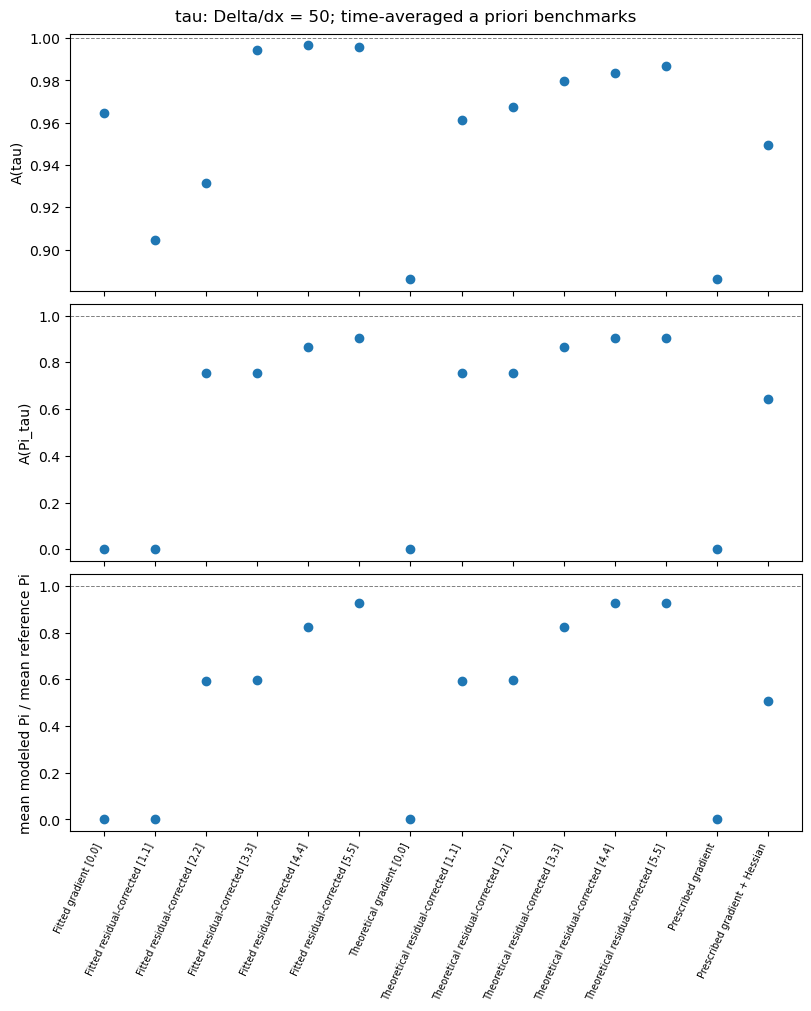

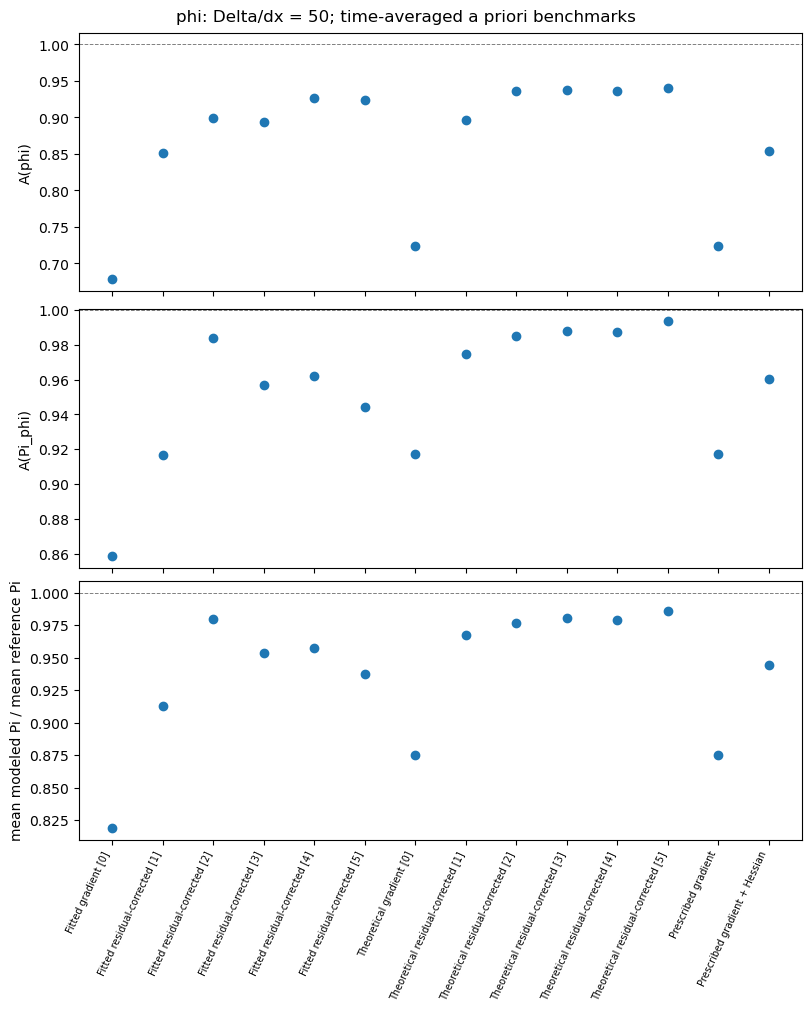

In [39]:
# %% Replacement flux analysis: paste ALL of this file into ONE new notebook cell.
# Exported from COnvection-FILTER-Copy2.ipynb; that notebook is the canonical source.
# Interrupt the old flux cell first. Keep the kernel and its fitted models alive.
# Requires completed data preparation, discovery, and discovery archiving (through
# notebook cell 28, counting Markdown). No setup or regression is repeated here.
# This cell calculates, archives to the existing analysis_run_dir, and plots.
# Alternative from the SAME live kernel: %run -i temp_flux_analysis_cell.py

_flux_required = ('run_controls', 'u_bar', 'tau', 'phi', 'b_filt', 'p_filt',
                  'RUN_BASELINE_RESIDUALS', 'archive_directory', 'restored_archive',
                  'analysis_run_dir')
_flux_missing = [name for name in _flux_required if name not in globals()]
if _flux_missing:
    raise RuntimeError('This cell needs the existing discovery kernel; missing: ' + ', '.join(_flux_missing))

# Copy execution controls so the original discovery metadata stays unchanged.
run_controls = dict(run_controls)
run_controls.update(flux_tile_size=64, flux_batch_size=8, flux_cache_mib=256)
run_controls['flux_workers'] = 32  # must fit the allocated CPU count

# Figure 2 benchmarks: parallel spatial tiles with reusable derivatives and terms.
from collections import OrderedDict, deque
from concurrent.futures import ThreadPoolExecutor
from itertools import islice
from threading import local
from time import perf_counter
import os
import inspect
import linecache

# Capture this executed cell, including notebook edits not yet saved to disk.
flux_executed_source = ''.join(linecache.getlines(inspect.currentframe().f_code.co_filename))
from itertools import product
from findiff import FinDiff
from SPIDER.commons.z3base import LiteralIndex, highest_index

flux_batch_size = int(run_controls.get('flux_batch_size', 8))
flux_cache_mib = int(run_controls.get('flux_cache_mib', 256))
flux_include_general = bool(run_controls.get('flux_include_general', False))
flux_tile_size = int(run_controls.get('flux_tile_size', 64))
flux_available_workers = int(run_controls.get('workers') or os.environ.get('SLURM_CPUS_PER_TASK')
    or (len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else 1))
flux_workers = int(run_controls.get('flux_workers') or min(8, flux_available_workers))
flux_margin = 8  # common interior beyond sixth-order finite-difference stencils
flux_mean_ratio_rtol = 1e-10
if min(flux_batch_size, flux_cache_mib, flux_tile_size, flux_workers) < 1:
    raise ValueError('Flux batch size, tile size, worker count and cache budget must be positive')
if flux_workers > flux_available_workers:
    raise ValueError('flux_workers exceeds the configured/allocated CPU count')

# Eq. (3.8) integrates moments before taking the ratio, not per-frame accuracies.
flux_times = np.asarray(t, dtype=float)
if flux_times.ndim != 1 or len(flux_times) < 2 or not np.isfinite(flux_times).all() or np.any(np.diff(flux_times) <= 0):
    raise ValueError('Paper averaging requires at least two finite, increasing times')
flux_time_weights = np.empty(len(flux_times), dtype=float)
flux_time_weights[0] = (flux_times[1]-flux_times[0])/2
flux_time_weights[-1] = (flux_times[-1]-flux_times[-2])/2
flux_time_weights[1:-1] = (flux_times[2:]-flux_times[:-2])/2
flux_time_weights /= flux_time_weights.sum()

# Keep the established common crop so discovered coefficients retain their meaning.
flux_fit_slice = (slice(pad_x, -pad_x), slice(pad_y, -pad_y)) if RUN_BASELINE_RESIDUALS else (slice(None), slice(None))
fx, fy = np.asarray(x)[flux_fit_slice[0]], np.asarray(y)[flux_fit_slice[1]]
flux_resolved = {'u': u_bar[flux_fit_slice], 'b': b_filt[flux_fit_slice], 'p': p_filt[flux_fit_slice]}
flux_measured = {'tau': tau[flux_fit_slice], 'phi': phi[flux_fit_slice]}
if min(len(fx), len(fy)) <= 2*flux_margin:
    raise ValueError('Not enough common interior for flux derivatives')
for coordinates, spacing in ((fx, dx), (fy, dy)):
    if not np.allclose(np.diff(coordinates), spacing):
        raise ValueError('Pointwise derivatives require uniform spatial coordinates')
for name, field in {**flux_resolved, **flux_measured}.items():
    if field.shape[:3] != (len(fx), len(fy), len(flux_times)):
        raise ValueError(f'Flux field/coordinate mismatch: {name}')
cut = (slice(flux_margin, -flux_margin),)*2

def paper_accuracy(moments):
    aa, bb, ab = moments
    return float(np.clip(ab/max(aa, bb), -1., 1.)) if max(aa, bb) > 0 else None

def flux_inner(a, b, weights):
    """Component contraction, uniform space mean, global time weights."""
    if a.shape != b.shape:
        raise ValueError('Flux moments require aligned fields')
    # Nonfinite inputs propagate into moments and are rejected once per tile.
    # Avoid rescanning both arrays before every contraction and every tau pairing.
    shape = (*a.shape[:3], -1)
    return float(np.einsum('xyti,xyti,t->', a.reshape(shape), b.reshape(shape), weights,
                           optimize=False)/(a.shape[0]*a.shape[1]))

def flux_mean(a, weights):
    return float(np.dot(a.mean(axis=(0, 1)), weights))

def flux_project(value, rank):
    # A scalar piece stores tr(tau), whose full-tensor norm is trace^2 / 2.
    if rank == 2:
        symmetric = (value + value.swapaxes(-1, -2))/2
        return symmetric - np.trace(symmetric, axis1=-2, axis2=-1)[..., None, None]*np.eye(2)/2
    return value

def flux_compile_term(term):
    """Compile Einstein contractions once; primes use canonical component/order keys."""
    if any(prime.derivative.torder for prime in term.primes):
        raise ValueError('Flux closure terms must be spatial-only')
    count = highest_index(term.all_indices()) + 1
    plan = []
    for assignment in product(range(2), repeat=count):
        literal = term.map_all_indices(lambda idx: LiteralIndex(assignment[idx.value])) if count else term
        primes = []
        for prime in literal.primes:
            orders = prime.derivative.get_spatial_orders()
            primes.append((prime.derivand.string, tuple(idx.value for idx in prime.derivand.indices),
                           tuple(orders[LiteralIndex(i)] for i in range(2))))
        plan.append((assignment[:term.rank], primes))
    return plan

# Each thread owns its finite-difference operators; input fields are read-only.
flux_worker_state = local()

class FluxTileEvaluator:
    """Cache derivatives AND contracted terms on a small spatial tile plus halo."""
    def __init__(self, start, stop, x0, x1, y0, y1):
        region = (slice(x0-flux_margin, x1+flux_margin),
                  slice(y0-flux_margin, y1+flux_margin), slice(start, stop))
        self.fields = {name: np.asarray(value[region], dtype=float)
                       for name, value in flux_resolved.items()}
        if RUN_BASELINE_RESIDUALS:
            for target, (_, name) in first_order_sources.items():
                self.fields[name] = np.asarray(second_order_datasets[target].data_dict[name][region], dtype=float)
        self.shape = self.fields['b'].shape
        self.cache, self.cache_bytes = OrderedDict(), 0
        self.limit = flux_cache_mib*1024**2
        self.peak_bytes = self.derivative_evaluations = self.prime_hits = self.term_hits = self.evictions = 0
        if not hasattr(flux_worker_state, 'operators'):
            flux_worker_state.operators = {}
        self.operators = flux_worker_state.operators

    def remember(self, key, value):
        # Values stored here own their data; nbytes accounts for retained memory.
        while self.cache and self.cache_bytes + value.nbytes > self.limit:
            _, old = self.cache.popitem(last=False)
            self.cache_bytes -= old.nbytes
            self.evictions += 1
        if value.nbytes <= self.limit:
            self.cache[key] = value
            self.cache_bytes += value.nbytes
            self.peak_bytes = max(self.peak_bytes, self.cache_bytes)
        return value

    def prime(self, key):
        cache_key = ('prime', key)
        if cache_key in self.cache:
            self.prime_hits += 1
            self.cache.move_to_end(cache_key)
            return self.cache[cache_key]
        name, components, orders = key
        field = self.fields[name][(slice(None),)*3 + components]
        if not any(orders):
            return field
        if orders not in self.operators:
            self.operators[orders] = FinDiff(
                *((axis, spacing, order) for axis, (spacing, order) in enumerate(zip((dx, dy), orders)) if order), acc=6)
        self.derivative_evaluations += 1
        return self.remember(cache_key, self.operators[orders](field))

    def term(self, term):
        cache_key = ('term', term)
        if cache_key in self.cache:
            self.term_hits += 1
            self.cache.move_to_end(cache_key)
            return self.cache[cache_key]
        result = np.zeros(tuple(n-2*flux_margin for n in self.shape[:2]) + (self.shape[2],) + (2,)*term.rank)
        # Form products on the retained interior, not on the discarded halo.
        for components, primes in flux_term_plans[term]:
            value = np.ones(result.shape[:3])
            for key in primes:
                value *= self.prime(key)[cut]
            result[(slice(None),)*3 + components] += value
        return self.remember(cache_key, result)

# Preserve every returned residual candidate, with its original archive ID.
flux_model_groups = {}
if flux_include_general:
    for target, entries in (('tau', tau_regression_results), ('phi', phi_regression_results)):
        for (irrep, count), entry in entries.items():
            key = (target, irrep, 'general')
            flux_model_groups.setdefault(key, {})[count] = dict(rank=entry['equation'].rank,
                gradient_name=None, baseline_coefficient=0., predictor_terms=entry['predictor_terms'],
                predictor_coefficients=entry['predictor_coefficients'])
if RUN_BASELINE_RESIDUALS:
    for key, entry in second_order_results.items():
        problem = entry['problem']
        flux_model_groups[key] = {index: dict(rank=problem.terms[0].rank,
            gradient_name=problem.gradient_name, baseline_coefficient=problem.coefficient,
            predictor_terms=problem.terms[1:], predictor_coefficients=fit['coefficients'])
            for index, fit in enumerate(entry['fits'])}

flux_term_plans = {}
for entries in flux_model_groups.values():
    for entry in entries.values():
        if len(entry['predictor_terms']) != len(entry['predictor_coefficients']):
            raise ValueError('Misaligned flux terms and coefficients')
        for term, coefficient in zip(entry['predictor_terms'], entry['predictor_coefficients']):
            if not np.isfinite(coefficient):
                raise ValueError('Nonfinite model coefficient')
            if coefficient != 0 and term not in flux_term_plans:
                flux_term_plans[term] = flux_compile_term(term)

for plan in flux_term_plans.values():
    for _, primes in plan:
        for _, _, orders in primes:
            # Sixth-order centered stencil radius from findiff's coefficient rule.
            if any(order and ((order+1)//2 + 2) > flux_margin for order in orders):
                raise ValueError('Flux term requires a wider spatial halo')

# Compile sparse coefficient use once, not once per spatial tile. Libraries can
# have thousands of inactive columns, which should never enter the tile hot path.
flux_group_plans = []
for key, entries in flux_model_groups.items():
    active_terms, baselines = {}, []
    for index, entry in entries.items():
        if entry['gradient_name'] is not None:
            baselines.append((index, entry['baseline_coefficient']))
        for term, coefficient in zip(entry['predictor_terms'], entry['predictor_coefficients']):
            if coefficient != 0:
                active_terms.setdefault(term, []).append((index, coefficient))
    flux_group_plans.append(dict(key=key, rank=next(iter(entries.values()))['rank'],
        indices=tuple(entries), baselines=tuple(baselines),
        active_terms=tuple((term, tuple(uses)) for term, uses in active_terms.items())))

flux_specs = []
for mode in sorted({key[2] for key in flux_model_groups}):
    groups = {}
    for key, entries in flux_model_groups.items():
        if key[2] == mode:
            groups[key[0], next(iter(entries.values()))['rank']] = [(key, index) for index in entries]
    if not {('tau', 0), ('tau', 2), ('phi', 1)} <= groups.keys():
        raise ValueError(f'Incomplete tau/phi candidate groups for {mode}')
    flux_specs += [dict(target='tau', family=mode, pieces=list(pair))
                   for pair in product(groups.get(('tau', 0), []), groups.get(('tau', 2), []))]
    flux_specs += [dict(target='phi', family=mode, pieces=[piece]) for piece in groups.get(('phi', 1), [])]
for target in ('tau', 'phi'):
    for order in (1, 2):
        flux_specs.append(dict(target=target, family='prescribed', order=order, pieces=[]))

# Columns: closure reference norm, model norm, cross moment;
#          flux reference norm, model norm, cross moment; mean reference, model Pi.
def flux_compute_tile(task):
    start, stop, x0, x1, y0, y1 = task
    weights = flux_time_weights[start:stop]
    evaluator = FluxTileEvaluator(*task)
    tile_x = fx[x0-flux_margin:x1+flux_margin]
    tile_y = fy[y0-flux_margin:y1+flux_margin]
    moments = np.zeros((len(flux_specs), 8))
    # These low-order gradients exactly retain the original gradient-baseline convention.
    velocity, scalar = evaluator.fields['u'], evaluator.fields['b']
    D = np.stack(np.gradient(velocity, tile_x, tile_y, axis=(0, 1), edge_order=2), axis=-2)[cut]
    strain = (D + D.swapaxes(-1, -2))/2
    grad_b = np.stack(np.gradient(scalar, tile_x, tile_y, axis=(0, 1), edge_order=2), axis=-1)[cut]
    measured = {target: np.asarray(field[x0:x1, y0:y1, start:stop], dtype=float)
                for target, field in flux_measured.items()}
    references = {'tau': -np.einsum('...ij,...ij->...', strain, measured['tau']),
                  'phi': -np.einsum('...i,...i->...', grad_b, measured['phi'])}
    reference_stats = {target: (flux_inner(measured[target], measured[target], weights),
        flux_inner(values, values, weights), flux_mean(values, weights)) for target, values in references.items()}
    gradients = {'tau': np.einsum('...ki,...kj->...ij', D, D),
                 'phi': np.einsum('...ki,...k->...i', D, grad_b)}
    piece_stats, piece_fluxes = {}, {}

    # Reuse compiled sparse plans, derivatives and terms across every family.
    # Only scalar flux fields survive a group; full candidate tensors are released.
    for group in flux_group_plans:
        key, rank = group['key'], group['rank']
        target = key[0]
        values = {index: np.zeros(grad_b.shape[:3] + (2,)*rank) for index in group['indices']}
        for index, coefficient in group['baselines']:
            baseline = gradients[target]
            if rank == 0:
                baseline = np.trace(baseline, axis1=-2, axis2=-1)
            values[index] += coefficient*baseline
        for term, uses in group['active_terms']:
            field = evaluator.term(term)
            for index, coefficient in uses:
                values[index] += coefficient*field
        for index in group['indices']:
            value = flux_project(values.pop(index), rank)
            if rank == 0:
                closure_bb = flux_inner(value, value, weights)/2
                closure_ab = flux_inner(np.trace(measured[target], axis1=-2, axis2=-1), value, weights)/2
                predicted = -np.trace(strain, axis1=-2, axis2=-1)*value/2
            else:
                closure_bb = flux_inner(value, value, weights)
                closure_ab = flux_inner(measured[target], value, weights)
                predicted = (-np.einsum('...ij,...ij->...', strain, value) if target == 'tau'
                             else -np.einsum('...i,...i->...', grad_b, value))
            piece = (key, index)
            piece_stats[piece] = np.array([closure_bb, closure_ab,
                flux_inner(predicted, predicted, weights), flux_inner(references[target], predicted, weights),
                flux_mean(predicted, weights)])
            piece_fluxes[piece] = predicted

    for index, spec in enumerate(flux_specs):
        if not spec['pieces']:
            continue
        target, pieces = spec['target'], spec['pieces']
        cbb, cab, pbb, pab, pm = sum(piece_stats[piece] for piece in pieces)
        # Trace and STF are orthogonal for closure norms, but their fluxes are not.
        if len(pieces) == 2:
            pbb += 2*flux_inner(piece_fluxes[pieces[0]], piece_fluxes[pieces[1]], weights)
        caa, paa, pr = reference_stats[target]
        moments[index] += [caa, max(0., cbb), cab, paa, max(0., pbb), pab, pr, pm]
    del piece_fluxes, piece_stats

    # Prescribed NGM2/NGM4 stress and the analogous Gaussian scalar-flux expansion.
    # Mixed Hessian derivatives appear twice in the contraction over k,m.
    hessians = {target: np.zeros_like(gradients[target]) for target in ('tau', 'phi')}
    for orders, multiplicity in (((2, 0), 1), ((1, 1), 2), ((0, 2), 1)):
        hu = np.stack([evaluator.prime(('u', (i,), orders))[cut] for i in range(2)], axis=-1)
        hb = evaluator.prime(('b', (), orders))[cut]
        hessians['tau'] += multiplicity*np.einsum('...i,...j->...ij', hu, hu)
        hessians['phi'] += multiplicity*hu*hb[..., None]
    for index, spec in enumerate(flux_specs):
        if spec['family'] != 'prescribed':
            continue
        target = spec['target']
        model = (delta**2/12)*gradients[target]
        if spec['order'] == 2:
            model += (delta**4/288)*hessians[target]
        predicted = (-np.einsum('...ij,...ij->...', strain, model) if target == 'tau'
                     else -np.einsum('...i,...i->...', grad_b, model))
        caa, paa, pr = reference_stats[target]
        moments[index] += [caa, flux_inner(model, model, weights), flux_inner(measured[target], model, weights),
            paa, flux_inner(predicted, predicted, weights), flux_inner(references[target], predicted, weights),
            pr, flux_mean(predicted, weights)]
    if not np.isfinite(moments).all():
        raise ValueError(f'Nonfinite flux moments in tile {task}')
    # Local uniform means become one global uniform mean. Every retained point
    # belongs to exactly one tile, including narrow final tiles along each axis.
    spatial_weight = ((x1-x0)*(y1-y0))/((len(fx)-2*flux_margin)*(len(fy)-2*flux_margin))
    return (moments*spatial_weight, evaluator.peak_bytes, evaluator.derivative_evaluations,
            evaluator.prime_hits, evaluator.term_hits, evaluator.evictions)

def flux_tile_results(pool, tasks):
    """Bound queued work and completed results; cancel queued tiles on interruption."""
    if pool is None:
        for task in tasks:
            yield flux_compute_tile(task)
        return
    tasks = iter(tasks)
    pending = deque(pool.submit(flux_compute_tile, task) for task in islice(tasks, 2*flux_workers))
    try:
        while pending:
            # Consume in submission order for deterministic accumulation.
            future = pending.popleft()
            yield future.result()
            task = next(tasks, None)
            if task is not None:
                pending.append(pool.submit(flux_compute_tile, task))
    finally:
        for future in pending:
            future.cancel()

flux_moments = np.zeros((len(flux_specs), 8))
flux_cache_peak_bytes = 0
flux_profile = []
flux_spatial_tiles = [(x0, min(x0+flux_tile_size, len(fx)-flux_margin),
                       y0, min(y0+flux_tile_size, len(fy)-flux_margin))
    for x0 in range(flux_margin, len(fx)-flux_margin, flux_tile_size)
    for y0 in range(flux_margin, len(fy)-flux_margin, flux_tile_size)]
print(f'Flux evaluation: {len(flux_spatial_tiles)} spatial tiles per time batch, '
      f'{flux_workers} threads, tile width {flux_tile_size}; all points and times retained.', flush=True)
flux_started = perf_counter()
pool = ThreadPoolExecutor(max_workers=flux_workers) if flux_workers > 1 else None
try:
    for start in range(0, len(flux_times), flux_batch_size):
        stop = min(start+flux_batch_size, len(flux_times))
        batch_started = last_progress = perf_counter()
        counters = np.zeros(4, dtype=np.int64)
        batch_peak = 0
        tasks = ((start, stop, *tile) for tile in flux_spatial_tiles)
        for completed, result in enumerate(flux_tile_results(pool, tasks), 1):
            tile_moments, peak, evaluations, prime_hits, term_hits, evictions = result
            flux_moments += tile_moments
            batch_peak = max(batch_peak, peak)
            counters += (evaluations, prime_hits, term_hits, evictions)
            if perf_counter()-last_progress >= 30:
                print(f'Flux tiles: times {start+1}-{stop}, {completed}/{len(flux_spatial_tiles)} tiles, '
                      f'{perf_counter()-batch_started:.1f}s elapsed', flush=True)
                last_progress = perf_counter()
        seconds = perf_counter()-batch_started
        flux_profile.append(dict(time_start=start, time_stop=stop, tiles=len(flux_spatial_tiles),
            seconds=seconds, cache_peak_bytes_per_tile=batch_peak, derivative_evaluations=int(counters[0]),
            derivative_cache_hits=int(counters[1]), term_cache_hits=int(counters[2]), cache_evictions=int(counters[3])))
        flux_cache_peak_bytes = max(flux_cache_peak_bytes, batch_peak)
        print(f'Flux moments: {stop}/{len(flux_times)} times, batch {seconds:.1f}s; '
              f'cache hits {counters[1]}, term hits {counters[2]}, evictions {counters[3]}', flush=True)
finally:
    if pool is not None:
        pool.shutdown(wait=True, cancel_futures=True)
flux_elapsed_seconds = perf_counter()-flux_started

flux_rows = []
for index, spec in enumerate(flux_specs):
    caa, cbb, cab, paa, pbb, pab, mean_ref, mean_model = flux_moments[index]
    if not np.isfinite(flux_moments[index]).all():
        raise ValueError('Nonfinite integrated flux moments')
    pieces = spec['pieces']
    budgets = [candidate for key, candidate in pieces]
    if spec['family'] == 'prescribed':
        order = spec['order']
        label = 'Prescribed gradient' if order == 1 else 'Prescribed gradient + Hessian'
        model_ids = [f"{spec['target']}|prescribed|order={order}"]
    else:
        order = None if spec['family'] == 'general' else (1 if all(b == 0 for b in budgets) else 2)
        label = spec['family'].capitalize() + (' gradient' if order == 1 else ' residual-corrected' if order == 2 else ' general')
        label += ' [' + ','.join(map(str, budgets)) + ']'
        model_ids = [f'{key[0]}|{key[1]}|{key[2]}|candidate={candidate}' for key, candidate in pieces]
    ratio_defined = paa > 0 and abs(mean_ref) > flux_mean_ratio_rtol*np.sqrt(paa)
    flux_rows.append(dict(id=str(index), target=spec['target'], family=spec['family'],
        model_order=order, label=label, model_ids=model_ids,
        default_plot=bool(not budgets or len(set(budgets)) == 1),
        closure_accuracy_A=paper_accuracy((caa, cbb, cab)), flux_accuracy_A=paper_accuracy((paa, pbb, pab)),
        time_mean_flux_reference=float(mean_ref), time_mean_flux_model=float(mean_model),
        mean_flux_ratio=float(mean_model/mean_ref) if ratio_defined else None,
        mean_flux_ratio_defined=bool(ratio_defined),
        closure_relative_l2_error=float(np.sqrt(max(0., caa+cbb-2*cab)/caa)) if caa > 0 else None,
        flux_relative_l2_error=float(np.sqrt(max(0., paa+pbb-2*pab)/paa)) if paa > 0 else None))
print(f'Flux benchmarks complete: {len(flux_rows)} model combinations; all {len(flux_times)} times included.', flush=True)


import csv
flux_created = datetime.now(timezone.utc)
flux_dir = analysis_run_dir / ('flux_'+flux_created.strftime('%Y%m%dT%H%M%S.%fZ')+'_'+uuid4().hex[:8])
flux_dir.mkdir(parents=True, exist_ok=False)
flux_report = dict(schema_version=4, created_utc=flux_created.isoformat(),
    workflow='batched Figure 2 closure and flux benchmarks', validation_status='a priori diagnostics on discovery data',
    discovery_archive=str(archive_directory), discovery_bundle=restored_archive,
    prescribed_coefficients=dict(gradient=float(delta**2/12), hessian=float(delta**4/288)),
    definitions=dict(Pi_tau='-sum_ij S_ij tau_ij', S_ij='(d_i ubar_j+d_j ubar_i)/2', Pi_phi='-sum_i phi_i d_i bbar',
        A='integral <reference:modeled> dt / max(integral <reference:reference> dt, integral <modeled:modeled> dt)',
        A_source='local SGS paper equations (3.8)-(3.9), pages 8-9; Figure 2',
        mean_flux_ratio='time-integrated spatial mean modeled Pi / reference Pi',
        prescribed_tau_first='(delta^2/12) (d_k u_i)(d_k u_j)',
        prescribed_tau_second='tau_first + (delta^4/288) (d_k d_m u_i)(d_k d_m u_j)',
        prescribed_phi_first='(delta^2/12) (d_k u_i)(d_k b)',
        prescribed_phi_second='phi_first + (delta^4/288) (d_k d_m u_i)(d_k d_m b)',
        prescribed_source='stress: paper (3.1)-(3.4); phi: analogous Gaussian expansion, not a claim from this stress-only paper',
        discovered_second='frozen fitted/theoretical gradient plus discovered residual; not assumed to equal prescribed Hessian'),
    settings=dict(spatial_margin=flux_margin, batch_size=flux_batch_size, derivative_cache_mib=flux_cache_mib,
        derivative_cache_peak_bytes=flux_cache_peak_bytes, include_general=flux_include_general,
        time_count=len(flux_times), temporal_subsampling=False,
        mean_ratio_rtol=flux_mean_ratio_rtol,
        accuracy_averaging='uniform spatial means, component contraction, trapezoidal time integral',
        gradients='numpy.gradient edge_order=2, matching fitted baseline construction',
        hessians_and_library_derivatives='findiff acc=6; spatial-only on common crop, interior margin 8',
        crop='original baseline fit crop shared by all models, then derivative margin' if RUN_BASELINE_RESIDUALS else 'shared-library grid then derivative margin',
        fit_crop_points=[int(pad_x), int(pad_y)] if RUN_BASELINE_RESIDUALS else [0, 0],
        tau_assembly='all trace/STF pairs within each family via orthogonal closure moments and flux cross moments',
        default_curves='prescribed models, uncorrected baselines, and matched-budget residual candidates; no error-based selection',
        scalar_convention='b is simulated buoyancy/temperature-like scalar; no dimensional conversion',
        zero_conventions='A null for two zero fields; mean ratio null for near-zero reference mean'),
    execution=dict(method='parallel spatial tiles, exact full-grid moments',
        workers=flux_workers, tile_size=flux_tile_size, tile_halo=flux_margin,
        cache_scope='per active tile; shared derivative and contracted-term budget',
        elapsed_seconds=flux_elapsed_seconds, batches=flux_profile),
    flux_source=dict(git_commit=source_git('rev-parse', 'HEAD'), git_status=source_git('status', '--porcelain'),
        executed_cell_file='executed_flux_cell.py' if flux_executed_source else None,
        executed_cell_sha256=hashlib.sha256(flux_executed_source.encode('utf-8')).hexdigest() if flux_executed_source else None,
        note='Discovery source snapshots describe the earlier fits; executed_flux_cell.py describes this flux evaluation.'),
    results=flux_rows, executed_helpers={})
if flux_executed_source:
    (flux_dir / 'executed_flux_cell.py').write_text(flux_executed_source, encoding='utf-8')
for name in ('paper_accuracy', 'flux_inner', 'flux_mean', 'flux_project', 'flux_compile_term', 'FluxTileEvaluator', 'flux_compute_tile', 'flux_tile_results'):
    try:
        flux_report['executed_helpers'][name] = inspect.getsource(globals()[name])
    except (OSError, TypeError):
        flux_report['executed_helpers'][name] = None
for source_file in archive_directory.glob('source_*'):
    (flux_dir / source_file.name).write_bytes(source_file.read_bytes())
np.savez_compressed(flux_dir / 'flux_moments.npz', t=flux_times, time_weights=flux_time_weights,
    x=fx[flux_margin:-flux_margin], y=fy[flux_margin:-flux_margin], moments=flux_moments,
    candidate_ids=np.asarray([row['id'] for row in flux_rows]),
    columns=np.asarray(['closure_ref_norm2','closure_model_norm2','closure_cross',
                        'flux_ref_norm2','flux_model_norm2','flux_cross','mean_ref_flux','mean_model_flux']))
(flux_dir / 'flux.json').write_text(json.dumps(restored_json_value(flux_report),
    indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
with (flux_dir / 'flux.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(flux_rows[0]))
    writer.writeheader()
    writer.writerows(flux_rows)
(flux_dir / 'COMPLETE').write_text(flux_created.isoformat(), encoding='utf-8')
print('Flux archive:', flux_dir.resolve())


if 'flux_rows' in globals():
    # At one scale, show the same three metrics as Figure 2, without time-series plots.
    import matplotlib.pyplot as plt
    for target in ('tau', 'phi'):
        rows = [row for row in flux_rows if row['target'] == target and row['default_plot']]
        fig, axes = plt.subplots(3, 1, figsize=(max(8, .45*len(rows)), 10), sharex=True, constrained_layout=True)
        for axis, metric, label in zip(axes,
            ('closure_accuracy_A', 'flux_accuracy_A', 'mean_flux_ratio'),
            (f'A({target})', f'A(Pi_{target})', 'mean modeled Pi / mean reference Pi')):
            axis.plot(range(len(rows)), [np.nan if row[metric] is None else row[metric] for row in rows], 'o')
            axis.axhline(1, color='gray', ls='--', lw=.7)
            axis.set(ylabel=label)
        axes[-1].set_xticks(range(len(rows)), [row['label'] for row in rows], rotation=65, ha='right', fontsize=7)
        fig.suptitle(f'{target}: Delta/dx = {delta/dx:g}; time-averaged a priori benchmarks')
        fig.savefig(flux_dir / f'paper_accuracy_{target}.png', dpi=180)
        plt.show()
        plt.close(fig)


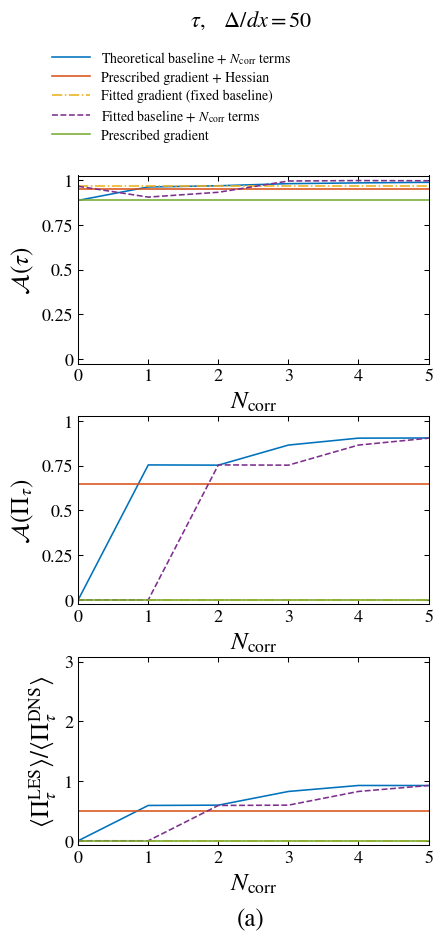

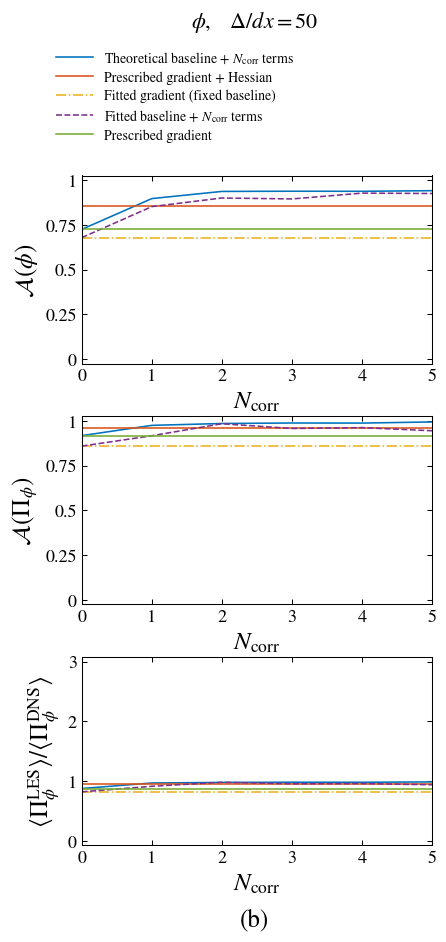

Figure 2 measurements at Delta/dx = 50
Source archive: /storage/home/hcoda1/2/ashelestov3/convection/thesis_runs/20261009T163805.093533Z_1c0c01d7/flux_20261009T183149.373380Z_0765d210
Time samples: 101; all archived trapezoidal weights verified.
A = integral <reference:model> dt / max(integral <reference:reference> dt, integral <model:model> dt).
Mean-flux ratio = time-averaged spatial mean modeled Pi / time-averaged spatial mean reference Pi.
Pi_tau = -S_ij tau_ij; Pi_phi = -phi_i d_i bbar; b is the simulated temperature-like scalar.
The x-axis is requested correction count, not filter width or asymptotic model order.
For tau, N_corr is the requested budget for EACH trace/STF fit, paired at equal budgets.
Horizontal baselines are fixed models, repeated only for visual comparison.
All candidate equations/coefficients remain in source_flux.json; mixed-budget pairs remain in metrics.csv.
These are a priori fits on discovery data, not independent validation or thesis model selection.

TAU

In [40]:
# %% Paste this entire file into ONE cell after the completed flux analysis.
# Or run in that SAME kernel: %run -i temp_flux_paper_analysis_cell.py
# Reads only the small completed flux archive. No fields, derivatives, fits, or
# fluxes are recomputed. Existing notebook state and archives are preserved.
#
# Optional overrides BEFORE running this cell:
# FIG2_ANALYSIS_CONFIG = {
#     'archive': str(flux_dir),  # defaults to the current kernel's flux_dir
#     'output_root': '/storage/scratch1/2/ashelestov3/rayleigh-benard/flux_analysis',
#     'mean_ratio_ylim': (0, 3), # paper limits; use (0, 1.1) for a closer view
#     'markers': False,         # paper-style lines; True marks evaluated models
# }
# The three measurements match paper Eqs. (3.8)-(3.9) and Figure 2(a).
# HERE the x-axis is requested correction count at ONE filter width, as requested;
# it is NOT the paper's delta = Delta / integral-length-scale axis.

import csv
import hashlib
import inspect
import json
import linecache
import re
import shutil
import traceback
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter, MaxNLocator

fig2_executed_source = ''.join(linecache.getlines(inspect.currentframe().f_code.co_filename))
fig2_config = dict(globals().get('FIG2_ANALYSIS_CONFIG', {}))
fig2_input = fig2_config.get('archive', globals().get('flux_dir'))
if fig2_input is None:
    raise RuntimeError('Run the flux calculation/archive first, or set FIG2_ANALYSIS_CONFIG["archive"].')
fig2_input = Path(fig2_input).expanduser().resolve()
if fig2_input.name == 'flux.json':
    fig2_input = fig2_input.parent
if not (fig2_input / 'COMPLETE').is_file():
    raise RuntimeError(f'Flux archive is not marked COMPLETE: {fig2_input}')
fig2_json_path = fig2_input / 'flux.json'
fig2_npz_path = fig2_input / 'flux_moments.npz'
fig2_json_bytes = fig2_json_path.read_bytes()
fig2_report = json.loads(fig2_json_bytes)
if fig2_report.get('schema_version') != 4:
    raise ValueError('This cell requires the completed schema-4 flux-moment archive.')

fig2_expected_columns = [
    'closure_ref_norm2', 'closure_model_norm2', 'closure_cross',
    'flux_ref_norm2', 'flux_model_norm2', 'flux_cross', 'mean_ref_flux', 'mean_model_flux',
]
with np.load(fig2_npz_path, allow_pickle=False) as fig2_npz:
    fig2_moments = np.asarray(fig2_npz['moments'], dtype=float)
    fig2_ids = [str(value) for value in fig2_npz['candidate_ids']]
    fig2_columns = [str(value) for value in fig2_npz['columns']]
    fig2_t = np.asarray(fig2_npz['t'], dtype=float)
    fig2_weights = np.asarray(fig2_npz['time_weights'], dtype=float)
if fig2_columns != fig2_expected_columns:
    raise ValueError('Unexpected moment column definitions; do not interpret these columns by position.')
if fig2_moments.shape != (len(fig2_ids), 8) or len(set(fig2_ids)) != len(fig2_ids):
    raise ValueError('Invalid moment table or duplicate candidate IDs.')
if not np.isfinite(fig2_moments).all():
    raise ValueError('Nonfinite archived flux moments.')
if (fig2_t.ndim != 1 or len(fig2_t) < 2 or not np.isfinite(fig2_t).all()
        or np.any(np.diff(fig2_t) <= 0) or fig2_weights.shape != fig2_t.shape):
    raise ValueError('Invalid archived times/weights.')
fig2_expected_weights = np.empty_like(fig2_t)
fig2_expected_weights[0] = (fig2_t[1]-fig2_t[0])/2
fig2_expected_weights[-1] = (fig2_t[-1]-fig2_t[-2])/2
fig2_expected_weights[1:-1] = (fig2_t[2:]-fig2_t[:-2])/2
fig2_expected_weights /= fig2_expected_weights.sum()
if not np.allclose(fig2_weights, fig2_expected_weights, rtol=1e-12, atol=1e-14):
    raise ValueError('The archive does not use the expected trapezoidal time average.')
fig2_lookup = dict(zip(fig2_ids, fig2_moments))
if {str(row['id']) for row in fig2_report['results']} != set(fig2_ids):
    raise ValueError('The JSON report and moment table refer to different candidate sets.')
fig2_mean_rtol = float(fig2_report['settings']['mean_ratio_rtol'])
fig2_physics = fig2_report['discovery_bundle']['scientific_settings']
fig2_delta_dx = float(fig2_physics['delta_dx'])


def fig2_metrics(moment):
    """Paper accuracy is a ratio of integrated moments, not mean frame accuracy."""
    caa, cbb, cab, paa, pbb, pab, mean_ref, mean_model = map(float, moment)
    for aa, bb, ab in ((caa, cbb, cab), (paa, pbb, pab)):
        if aa < 0 or bb < 0:
            raise ValueError('Negative squared norm in archived moments.')
        tolerance = 1e-10*max(aa, bb, abs(ab), np.finfo(float).tiny)
        if abs(ab) > np.sqrt(aa)*np.sqrt(bb) + tolerance:
            raise ValueError('Archived cross moment violates the Cauchy-Schwarz bound.')
    ratio_defined = paa > 0 and abs(mean_ref) > fig2_mean_rtol*np.sqrt(paa)
    return dict(
        closure_accuracy_A=float(np.clip(cab/max(caa, cbb), -1, 1)) if max(caa, cbb) > 0 else None,
        flux_accuracy_A=float(np.clip(pab/max(paa, pbb), -1, 1)) if max(paa, pbb) > 0 else None,
        mean_flux_ratio=mean_model/mean_ref if ratio_defined else None,
        closure_relative_l2_error=np.sqrt(max(0., caa+cbb-2*cab)/caa) if caa > 0 else None,
        flux_relative_l2_error=np.sqrt(max(0., paa+pbb-2*pab)/paa) if paa > 0 else None,
        time_mean_flux_reference=mean_ref, time_mean_flux_model=mean_model,
    )


def fig2_same_number(a, b):
    if a is None or b is None:
        return a is None and b is None
    return bool(np.isclose(a, b, rtol=1e-9, atol=1e-12))


def fig2_number(value):
    return 'undefined' if value is None else f'{value:.6g}'


fig2_rows = []
fig2_sequences = {target: {'fitted': {}, 'theoretical': {}} for target in ('tau', 'phi')}
fig2_prescribed = {target: {} for target in ('tau', 'phi')}
for fig2_original_row in fig2_report['results']:
    fig2_row = dict(fig2_original_row)
    fig2_values = fig2_metrics(fig2_lookup[str(fig2_row['id'])])
    for fig2_metric, fig2_value in fig2_values.items():
        if not fig2_same_number(fig2_row.get(fig2_metric), fig2_value):
            raise ValueError(f'JSON/moment mismatch: candidate {fig2_row["id"]}, {fig2_metric}.')
    fig2_row.update(fig2_values)
    fig2_row['correction_budget'] = None
    fig2_row['plotted'] = False
    fig2_target, fig2_family = fig2_row['target'], fig2_row['family']
    if fig2_target not in fig2_sequences:
        raise ValueError(f'Unknown target {fig2_target}.')
    if fig2_family in ('fitted', 'theoretical'):
        fig2_matches = [re.search(r'\|candidate=(\d+)$', model_id) for model_id in fig2_row['model_ids']]
        if not fig2_matches or any(match is None for match in fig2_matches):
            raise ValueError('Cannot identify requested correction budgets from model IDs.')
        fig2_budgets = [int(match.group(1)) for match in fig2_matches]
        if len(fig2_budgets) != (2 if fig2_target == 'tau' else 1):
            raise ValueError('Unexpected trace/STF or vector candidate assembly.')
        if len(set(fig2_budgets)) == 1:
            fig2_budget = fig2_budgets[0]
            if fig2_budget in fig2_sequences[fig2_target][fig2_family]:
                raise ValueError('Duplicate family/target/correction budget.')
            fig2_row.update(correction_budget=fig2_budget, plotted=True)
            fig2_sequences[fig2_target][fig2_family][fig2_budget] = fig2_row
    elif fig2_family == 'prescribed':
        fig2_order = int(fig2_row['model_order'])
        if fig2_order in fig2_prescribed[fig2_target]:
            raise ValueError('Duplicate prescribed model.')
        fig2_row['plotted'] = True
        fig2_prescribed[fig2_target][fig2_order] = fig2_row
    fig2_rows.append(fig2_row)

for fig2_target in ('tau', 'phi'):
    if set(fig2_prescribed[fig2_target]) != {1, 2}:
        raise ValueError(f'Missing prescribed first/second-order {fig2_target} model.')
    for fig2_family in ('fitted', 'theoretical'):
        if 0 not in fig2_sequences[fig2_target][fig2_family]:
            raise ValueError(f'Missing {fig2_family} {fig2_target} baseline; use a run with baseline/residual discovery.')
if not any(k > 0 for groups in fig2_sequences.values() for seq in groups.values() for k in seq):
    raise ValueError('No residual corrections to plot against correction count.')

# Paper/MATLAB color order and line styles. Labels identify OUR models, not the
# NGMR/Smagorinsky/similarity models used in the paper's different experiment.
fig2_styles = {
    'theoretical_sequence': dict(color='#0072BD', linestyle='-', label=r'Theoretical baseline + $N_{\rm corr}$ terms'),
    'prescribed_second': dict(color='#D95319', linestyle='-', label='Prescribed gradient + Hessian'),
    'fitted_baseline': dict(color='#EDB120', linestyle='-.', label='Fitted gradient (fixed baseline)'),
    'fitted_sequence': dict(color='#7E2F8E', linestyle='--', label=r'Fitted baseline + $N_{\rm corr}$ terms'),
    'prescribed_first': dict(color='#77AC30', linestyle='-', label='Prescribed gradient'),
}
fig2_metrics_to_plot = ('closure_accuracy_A', 'flux_accuracy_A', 'mean_flux_ratio')
fig2_text = [
    f'Figure 2 measurements at Delta/dx = {fig2_delta_dx:g}',
    f'Source archive: {fig2_input}',
    f'Time samples: {len(fig2_t)}; all archived trapezoidal weights verified.',
    'A = integral <reference:model> dt / max(integral <reference:reference> dt, integral <model:model> dt).',
    'Mean-flux ratio = time-averaged spatial mean modeled Pi / time-averaged spatial mean reference Pi.',
    'Pi_tau = -S_ij tau_ij; Pi_phi = -phi_i d_i bbar; b is the simulated temperature-like scalar.',
    'The x-axis is requested correction count, not filter width or asymptotic model order.',
    'For tau, N_corr is the requested budget for EACH trace/STF fit, paired at equal budgets.',
    'Horizontal baselines are fixed models, repeated only for visual comparison.',
    'All candidate equations/coefficients remain in source_flux.json; mixed-budget pairs remain in metrics.csv.',
    'These are a priori fits on discovery data, not independent validation or thesis model selection.',
    '',
]
for fig2_target in ('tau', 'phi'):
    fig2_text += [fig2_target.upper(), 'model                                  A(closure)    A(flux)       mean ratio    relative L2(closure)']
    for fig2_row in (row for row in fig2_rows if row['target'] == fig2_target and row['plotted']):
        fig2_text.append(f"{fig2_row['label']:<38} " + ' '.join(
            f'{fig2_number(fig2_row[key]):<13}' for key in (*fig2_metrics_to_plot, 'closure_relative_l2_error')))
    for fig2_family in ('fitted', 'theoretical'):
        fig2_seq = fig2_sequences[fig2_target][fig2_family]
        fig2_base = fig2_seq[0]
        fig2_worse = [str(k) for k, row in sorted(fig2_seq.items()) if k > 0
            and row['closure_accuracy_A'] is not None and fig2_base['closure_accuracy_A'] is not None
            and row['closure_accuracy_A'] < fig2_base['closure_accuracy_A'] - 1e-10]
        if fig2_worse:
            fig2_text.append(f'{fig2_family}: closure accuracy is BELOW its baseline at budgets ' + ', '.join(fig2_worse) + '.')
        fig2_text.append(f'{fig2_family}: no best budget is selected; every available matched budget is shown.')
    fig2_text.append('')
fig2_text += [
    'Interpretation: a good stress fit can still predict poor energy transfer.',
    'For ideal incompressible 2D flow, the first-gradient stress has zero contraction with S;',
    'near-zero first-order Pi_tau is therefore expected. This does not imply zero Pi_phi.',
    'Prescribed second order means gradient + Hessian. Discovered residuals can contain other terms.',
    'A fitted coefficient minimizes its weak-form regression objective, not these pointwise metrics.',
]

# Fresh scratch output, regardless of where the older discovery archive lives.
fig2_output_root = Path(fig2_config.get('output_root',
    '/storage/scratch1/2/ashelestov3/rayleigh-benard/flux_analysis')).expanduser().resolve()
fig2_output = fig2_output_root / ('figure2_count_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S.%fZ') + '_' + uuid4().hex[:8])
fig2_output.mkdir(parents=True, exist_ok=False)
(fig2_output / 'source_flux.json').write_bytes(fig2_json_bytes)
shutil.copyfile(fig2_npz_path, fig2_output / 'source_flux_moments.npz')
if fig2_executed_source:
    (fig2_output / 'executed_analysis_cell.py').write_text(fig2_executed_source, encoding='utf-8')

fig2_plot_records, fig2_notices = [], []
fig2_rc = {
    'font.family': 'serif', 'font.serif': ['STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'text.usetex': False, 'font.size': 13,
    'axes.linewidth': .75, 'axes.labelsize': 18, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'lines.linewidth': 1.15, 'savefig.facecolor': 'white', 'figure.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}
try:
    with plt.rc_context(fig2_rc):
        for fig2_panel, fig2_target in zip(('a', 'b'), ('tau', 'phi')):
            fig2_kmax = max(k for groups in fig2_sequences.values() for seq in groups.values() for k in seq)
            fig2_x = np.arange(fig2_kmax+1)
            fig2_curves = [
                ('theoretical_sequence', fig2_sequences[fig2_target]['theoretical'], False),
                ('prescribed_second', fig2_prescribed[fig2_target][2], True),
                ('fitted_baseline', fig2_sequences[fig2_target]['fitted'][0], True),
                ('fitted_sequence', fig2_sequences[fig2_target]['fitted'], False),
                ('prescribed_first', fig2_prescribed[fig2_target][1], True),
            ]
            fig2_figure, fig2_axes = plt.subplots(3, 1, figsize=(4.8, 9.5), sharex=True)
            fig2_figure.subplots_adjust(left=.24, right=.97, bottom=.105, top=.81, hspace=.28)
            fig2_symbol = r'\tau' if fig2_target == 'tau' else r'\phi'
            fig2_ylabels = (rf'$\mathcal{{A}}({fig2_symbol})$',
                           rf'$\mathcal{{A}}(\Pi_{{{fig2_symbol}}})$',
                           rf'$\langle\Pi_{{{fig2_symbol}}}^{{\mathrm{{LES}}}}\rangle/\langle\Pi_{{{fig2_symbol}}}^{{\mathrm{{DNS}}}}\rangle$')
            for fig2_axis, fig2_metric, fig2_ylabel in zip(fig2_axes, fig2_metrics_to_plot, fig2_ylabels):
                fig2_plotted_values = []
                for fig2_key, fig2_data, fig2_constant in fig2_curves:
                    fig2_curve_rows = [fig2_data if fig2_constant else fig2_data.get(int(k)) for k in fig2_x]
                    fig2_y = [np.nan if row is None or row[fig2_metric] is None else row[fig2_metric] for row in fig2_curve_rows]
                    fig2_axis.plot(fig2_x, fig2_y, **fig2_styles[fig2_key],
                        marker='o' if fig2_config.get('markers', False) and not fig2_constant else None, markersize=3)
                    fig2_plotted_values.extend(value for value in fig2_y if np.isfinite(value))
                    fig2_plot_records.append(dict(target=fig2_target, metric=fig2_metric,
                        curve=fig2_key, horizontal_reference=fig2_constant, x=fig2_x.tolist(),
                        y=[float(value) if np.isfinite(value) else None for value in fig2_y],
                        candidate_ids=[str(row['id']) if row is not None else None for row in fig2_curve_rows]))
                if fig2_metric == 'mean_flux_ratio':
                    fig2_limits = tuple(fig2_config.get('mean_ratio_ylim', (0, 3)))
                    if len(fig2_limits) != 2 or not np.isfinite(fig2_limits).all() or fig2_limits[0] >= fig2_limits[1]:
                        raise ValueError('mean_ratio_ylim must contain two finite increasing limits.')
                    fig2_lo, fig2_hi = map(float, fig2_limits)
                    fig2_ticks = [0, 1, 2, 3] if fig2_limits == (0, 3) else None
                else:
                    fig2_lo, fig2_hi = 0., 1.
                    fig2_ticks = [0, .25, .5, .75, 1]
                fig2_span = fig2_hi-fig2_lo
                if fig2_plotted_values and (min(fig2_plotted_values) < fig2_lo-.025*fig2_span
                                           or max(fig2_plotted_values) > fig2_hi+.025*fig2_span):
                    fig2_lo = min(fig2_lo, min(fig2_plotted_values))
                    fig2_hi = max(fig2_hi, max(fig2_plotted_values))
                    fig2_ticks = None
                    fig2_notices.append(f'Expanded {fig2_target} {fig2_metric} limits to retain all values.')
                fig2_padding = .025*(fig2_hi-fig2_lo)
                fig2_axis.set(ylim=(fig2_lo-fig2_padding, fig2_hi+fig2_padding),
                              xlim=(0, fig2_kmax), ylabel=fig2_ylabel)
                if fig2_ticks is not None:
                    fig2_axis.set_yticks(fig2_ticks)
                fig2_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'))
                fig2_axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
                fig2_axis.tick_params(direction='in', top=True, right=True, length=3.5, width=.75,
                                     labelbottom=True)
                fig2_axis.set_xlabel(r'$N_{\mathrm{corr}}$')
                fig2_axis.grid(False)
            fig2_handles, fig2_labels = fig2_axes[0].get_legend_handles_labels()
            fig2_figure.legend(fig2_handles, fig2_labels, loc='upper left', bbox_to_anchor=(.16, .956),
                              frameon=False, fontsize=10, handlelength=2.7, labelspacing=.35)
            fig2_figure.text(.6, .985, rf'${fig2_symbol},\quad \Delta/dx={fig2_delta_dx:g}$',
                             ha='center', va='top', fontsize=16)
            fig2_figure.text(.6, .02, f'({fig2_panel})', ha='center', fontsize=18)
            for fig2_extension in ('png', 'pdf', 'svg'):
                fig2_figure.savefig(fig2_output / f'figure2_{fig2_target}_vs_correction_count.{fig2_extension}', dpi=300)
            plt.show()
            plt.close(fig2_figure)

    fig2_csv_columns = ['id', 'target', 'family', 'label', 'model_order', 'correction_budget', 'plotted',
        *fig2_metrics_to_plot, 'closure_relative_l2_error', 'flux_relative_l2_error',
        'time_mean_flux_reference', 'time_mean_flux_model', 'model_ids']
    with (fig2_output / 'metrics.csv').open('w', newline='', encoding='utf-8') as fig2_stream:
        fig2_writer = csv.DictWriter(fig2_stream, fieldnames=fig2_csv_columns)
        fig2_writer.writeheader()
        for fig2_row in fig2_rows:
            fig2_record = {key: fig2_row.get(key) for key in fig2_csv_columns}
            fig2_record['model_ids'] = json.dumps(fig2_row['model_ids'], ensure_ascii=False)
            fig2_writer.writerow(fig2_record)
    fig2_text.extend(fig2_notices)
    fig2_analysis_text = '\n'.join(fig2_text) + '\n'
    (fig2_output / 'analysis.txt').write_text(fig2_analysis_text, encoding='utf-8')
    fig2_manifest = dict(created_utc=datetime.now(timezone.utc).isoformat(),
        source_archive=str(fig2_input), source_flux_sha256=hashlib.sha256(fig2_json_bytes).hexdigest(),
        source_moments_sha256=hashlib.sha256(fig2_npz_path.read_bytes()).hexdigest(),
        executed_cell_sha256=hashlib.sha256(fig2_executed_source.encode('utf-8')).hexdigest() if fig2_executed_source else None,
        measurements=fig2_report['definitions'], delta_dx=fig2_delta_dx,
        x_axis='requested residual correction budget at fixed filter width; matched trace/STF budgets',
        reference='local SGS paper Figure 2(a), equations (3.8)-(3.9); x-axis intentionally adapted',
        mean_ratio_ylim=list(fig2_config.get('mean_ratio_ylim', (0, 3))),
        plot_settings=dict(markers=bool(fig2_config.get('markers', False)),
            figure_inches=[4.8, 9.5], rc=fig2_rc),
        colors_and_lines=fig2_styles, plotted_curves=fig2_plot_records, notices=fig2_notices,
        validation='archived moment/report consistency checked; not independent scientific validation')
    (fig2_output / 'analysis.json').write_text(json.dumps(fig2_manifest, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    (fig2_output / 'COMPLETE').write_text(datetime.now(timezone.utc).isoformat(), encoding='utf-8')
except BaseException:
    (fig2_output / 'FAILED').write_text(traceback.format_exc(), encoding='utf-8')
    raise

print(fig2_analysis_text)
print('Paper-style analysis and figures saved to:', fig2_output)


## Plots

Original plotting controls and diagnostics follow the numerical work. Repeated copies of the same figure block have been removed.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
 
def compute_derivatives_and_residuals(u, v, p, b, tau, x, y, dt, kappa):
    """
    Computes terms of the momentum equations using np.gradient (central difference).
    Returns the residuals for U and V momentum equations.
    """
    print("Computing derivatives...")
    # Grid Spacing
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    # --- 1. Temporal Derivative (d/dt) ---
    # axis=2 is time
    u_t = np.gradient(u, dt, axis=2)
    v_t = np.gradient(v, dt, axis=2)
    # --- 2. Spatial Derivatives (First Order) ---
    # axis=0 is X, axis=1 is Y
    u_x = np.gradient(u, dx, axis=0)
    u_y = np.gradient(u, dy, axis=1)
    v_x = np.gradient(v, dx, axis=0)
    v_y = np.gradient(v, dy, axis=1)
    p_x = np.gradient(p, dx, axis=0)
    p_y = np.gradient(p, dy, axis=1)
    # --- 3. Viscous Terms (Laplacian) ---
    u_xx = np.gradient(u_x, dx, axis=0)
    u_yy = np.gradient(u_y, dy, axis=1)
    lap_u = u_xx + u_yy
    v_xx = np.gradient(v_x, dx, axis=0)
    v_yy = np.gradient(v_y, dy, axis=1)
    lap_v = v_xx + v_yy
    # --- 4. Subgrid Stress Divergence (div Tau) ---
    # tau shape: (Nx, Ny, Nt, 2, 2) -> (xx, xy; yx, yy)
    tau_xx = tau[..., 0, 0]
    tau_xy = tau[..., 0, 1]
    tau_yy = tau[..., 1, 1]
    # div(Tau)_x = d(tau_xx)/dx + d(tau_xy)/dy
    dtxx_dx = np.gradient(tau_xx, dx, axis=0)
    dtxy_dy = np.gradient(tau_xy, dy, axis=1)
    div_tau_x = dtxx_dx + dtxy_dy
    # div(Tau)_y = d(tau_xy)/dx + d(tau_yy)/dy
    dtxy_dx = np.gradient(tau_xy, dx, axis=0)
    dtyy_dy = np.gradient(tau_yy, dy, axis=1)
    div_tau_y = dtxy_dx + dtyy_dy
 
    # --- 5. Assemble Residuals ---
    # U-Momentum: du/dt + u*du/dx + v*du/dy = -dp/dx + nu*Lap(u) - div(Tau)_x
    # Residual = LHS - RHS
    # Note: If tau is defined as (Mean(uu) - Mean(u)Mean(u)), it sits on the RHS with a negative sign
    # as usually written in LES: d_t u_bar + div(u_bar u_bar) = ... - div(tau)
    adv_u = (u * u_x) + (v * u_y)
    # Res_U = Time + Advection + Pressure - Diffusion + Div(Tau)
    # Signs depend on how you move terms. Here we calculate:
    # Error = (Time + Advec) - (Pressure + Diffusion + Stress)
    # Check signs: Pressure is usually -dp/dx. Diffusion is +nu*Lap.
    # Standard Form: du/dt + u.grad(u) = -grad(p) + nu*Lap(u) - div(tau)
    # So: Res = (du/dt + u.grad(u)) - (-grad(p) + nu*Lap(u) - div(tau))
    Res_U = (u_t + adv_u) - (-p_x + kappa * lap_u - div_tau_x)
    # V-Momentum: dv/dt + u*dv/dx + v*dv/dy = -dp/dy + nu*Lap(v) + Buoyancy - div(Tau)_y
    # Buoyancy term usually +b (or T) in vertical direction
    adv_v = (u * v_x) + (v * v_y)
    Res_V = (v_t + adv_v) - (-p_y + kappa * lap_v + b - div_tau_y)
    return Res_U, Res_V
 
# --- EXECUTION ---

print("Calculating Residuals...")

# Unpack your variables
# u_bar shape is (Nx, Ny, Nt, 2)
_u = u_bar[..., 0]
_v = u_bar[..., 1]
_p = p_filt
_b = b_filt

# FIX: Use 'xp' and 'yp' (the actual filtered coordinates) instead of 'x' and 'y'
# 'x' and 'y' might have been overwritten by the SRDataset cell
res_u, res_v = compute_derivatives_and_residuals(_u, _v, _p, _b, tau, xp, yp, dt, kappa)

print("Calculation Complete.")
print(f"Residual U - Mean: {np.mean(np.abs(res_u)):.6f}, Max: {np.max(np.abs(res_u)):.6f}")
print(f"Residual V - Mean: {np.mean(np.abs(res_v)):.6f}, Max: {np.max(np.abs(res_v)):.6f}")

# --- PLOTTING ---
t_idx = 50

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])

im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])

plt.show()
 


In [ ]:
# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt

# === Parameters ===
field_name = 'u'      # Choose: 'u', 'v', 'p', 'b', or 'w'
time_step_idx = 25    # Choose a timestep to visualize (e.g., 50)
cmap = 'RdBu_r'       # Colormap (Red-Blue is good for velocity/divergence)

# === Select Data ===
if field_name == 'u':
    raw_data = U[:, :, time_step_idx]
    filt_data = tau_xx[:, :, time_step_idx] + tau_yy[:, :, time_step_idx]
    title_txt = "Horizontal Velocity (U)"
elif field_name == 'v':
    raw_data = V[:, :, time_step_idx]
    filt_data = v_filt[:, :, time_step_idx]
    title_txt = "Vertical Velocity (V)"
elif field_name == 'b':
    raw_data = B[:, :, time_step_idx]
    filt_data = b_filt[:, :, time_step_idx]
    title_txt = "Buoyancy (B)"
elif field_name == 'p':
    raw_data = P[:, :, time_step_idx]
    filt_data = p_filt[:, :, time_step_idx]
    title_txt = "Pressure (P)"
elif field_name == 'w':
    raw_data = W[:, :, time_step_idx]
    filt_data = w_filt[:, :, time_step_idx]
    title_txt = "Vorticity (W)"

# === Plotting ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Raw
# We transpose (.T) so that X is horizontal and Y is vertical
im1 = axes[0].imshow(raw_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title(f"Raw {title_txt} (t={time_step_idx})", fontsize=14)
axes[0].set_ylabel("Y (Grid Points)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Plot Filtered
im2 = axes[1].imshow(filt_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title(f"Filtered {title_txt} (t={time_step_idx})", fontsize=14)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# === Optional: Zoom in to see the smoothing ===
# Use this to see the pixel-level difference
print("Zooming in on a small section...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Zoom slice
ys, ye = 100, 300  # Y-slice
xs, xe = 1000, 1200 # X-slice

im3 = axes[0].imshow(raw_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title("Zoom: Raw", fontsize=14)

im4 = axes[1].imshow(filt_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title("Zoom: Filtered", fontsize=14)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residuals (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(U_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(V_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw
extent_raw = [x[0], x[-1], y[0], y[-1]]

# --- 2. Filtered Divergence ---
# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays
dx_filt = float(xp[1] - xp[0])
dy_filt = float(yp[1] - yp[0])

u_filt_t = u_bar[:, :, t_idx,0]
v_filt_t = u_bar[:, :, t_idx,1]

du_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)
dv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)
div_filt = du_dx_filt + dv_dy_filt
extent_filt = [xp[0], xp[-1], yp[0], yp[-1]]

print(f"Raw Divergence      - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Filtered Divergence - Mean: {np.mean(np.abs(div_filt)):.6e}, Max: {np.max(np.abs(div_filt)):.6e}")

# --- 3. 2x1 Plotting ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw)) * 0.5 
v_limit_filt = np.max(np.abs(div_filt)) * 0.5

# Plot Raw
im1 = axes[0].imshow(
    div_raw.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_raw,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)
axes[0].set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
axes[0].set_ylabel("Y")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="Divergence")

# Plot Filtered
im2 = axes[1].imshow(
    div_filt.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_filt,
    vmax=v_limit_filt
)
axes[1].set_title(f"Filtered Continuity Residual ($\\nabla \\cdot \\bar{{\\mathbf{{u}}}}$) at t={t_idx}", fontsize=14)
axes[1].set_ylabel("Y")
axes[1].set_xlabel("X")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Divergence")

plt.tight_layout()
plt.show()

In [ ]:
print("omega:", np.mean(np.sqrt(w_filt**2)))
# Calculate RMS for both raw and filtered divergence
rms_div_raw = np.sqrt(np.mean(div_raw**2))
rms_div_filt = np.sqrt(np.mean(div_filt**2))

print(f"RMS Divergence (Raw):      {rms_div_raw:.6e}")
print(f"RMS Divergence (Filtered): {rms_div_filt:.6e}")

In [ ]:
if 'flux_rows' in globals():
    # At one scale, show the same three metrics as Figure 2, without time-series plots.
    import matplotlib.pyplot as plt
    for target in ('tau', 'phi'):
        rows = [row for row in flux_rows if row['target'] == target and row['default_plot']]
        fig, axes = plt.subplots(3, 1, figsize=(max(8, .45*len(rows)), 10), sharex=True, constrained_layout=True)
        for axis, metric, label in zip(axes,
            ('closure_accuracy_A', 'flux_accuracy_A', 'mean_flux_ratio'),
            (f'A({target})', f'A(Pi_{target})', 'mean modeled Pi / mean reference Pi')):
            axis.plot(range(len(rows)), [np.nan if row[metric] is None else row[metric] for row in rows], 'o')
            axis.axhline(1, color='gray', ls='--', lw=.7)
            axis.set(ylabel=label)
        axes[-1].set_xticks(range(len(rows)), [row['label'] for row in rows], rotation=65, ha='right', fontsize=7)
        fig.suptitle(f'{target}: Delta/dx = {delta/dx:g}; time-averaged a priori benchmarks')
        fig.savefig(flux_dir / f'paper_accuracy_{target}.png', dpi=180)
        plt.show()
        plt.close(fig)


In [ ]:
# Archive-only Figure 2 plots; no data loading, filtering, regression, or flux reevaluation.
if globals().get('SWEEP_COMPARE_CONFIG'):
    import json
    import csv
    from pathlib import Path
    from datetime import datetime, timezone
    from uuid import uuid4
    import numpy as np
    import matplotlib.pyplot as plt
    compare_config = dict(SWEEP_COMPARE_CONFIG)
    compare_root = Path(compare_config['root']).resolve()
    reference_length = compare_config.get('reference_length')
    if reference_length is not None and (not np.isfinite(reference_length) or reference_length <= 0):
        raise ValueError('reference_length must be finite and positive')
    comparison_rows, comparison_skipped = [], []
    seen, signature = set(), None
    for report_path in sorted(compare_root.rglob('flux.json')):
        if not (report_path.parent / 'COMPLETE').is_file():
            comparison_skipped.append(dict(path=str(report_path), reason='incomplete archive'))
            continue
        report = json.loads(report_path.read_text(encoding='utf-8'))
        if report.get('schema_version') != 4:
            comparison_skipped.append(dict(path=str(report_path), reason='different flux method/schema; earlier archives preserved'))
            continue
        parent_run = report_path.parent.parent
        if (parent_run / 'execution.json').is_file() and not (parent_run / 'COMPLETE').is_file():
            comparison_skipped.append(dict(path=str(report_path), reason='batch execution incomplete'))
            continue
        discovery = report['discovery_bundle']
        controls = {k: v for k, v in discovery['run_controls'].items()
                    if k not in {'run_dir','output_root','delta_dx','workers','flux_batch_size','flux_cache_mib','flux_workers','flux_tile_size'}}
        physics = discovery['scientific_settings']
        data = dict(discovery['data'])
        data.pop('filtered_velocity_shape', None)
        settings = {k: v for k, v in report['settings'].items()
                    if k not in {'batch_size','derivative_cache_mib','derivative_cache_peak_bytes','fit_crop_points'}}
        current_signature = json.dumps(dict(data=data, controls=controls,
            physical_parameters={k: physics[k] for k in ('dx','dy','dt','Rayleigh','Prandtl','alpha')},
            flux_settings=settings), sort_keys=True)
        if signature is not None and current_signature != signature:
            raise ValueError('Mixed inputs/settings in comparison root; use one dedicated directory per sweep')
        signature = current_signature
        for row in report['results']:
            if not row['default_plot'] and not compare_config.get('include_corrections', False):
                continue
            family = ' + '.join(row['model_ids'])
            key = (family, float(physics['delta']))
            if key in seen:
                raise ValueError(f'Duplicate model/scale {key}; select one run per scale')
            seen.add(key)
            comparison_rows.append(dict(target=row['target'], model_family=family, label=row['label'],
                family=row['family'], model_order=row['model_order'], delta=physics['delta'], delta_dx=physics['delta_dx'],
                axis_scale=physics['delta']/reference_length if reference_length else physics['delta_dx'],
                closure_accuracy_A=row['closure_accuracy_A'], flux_accuracy_A=row['flux_accuracy_A'],
                mean_flux_ratio=row['mean_flux_ratio'], source_archive=str(report_path)))
    if not comparison_rows:
        raise ValueError(f'No completed batched flux archives under {compare_root}; skipped: {comparison_skipped}')
    comparison_dir = compare_root / ('comparison_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid4().hex[:8])
    comparison_dir.mkdir(parents=True, exist_ok=False)
    for target in ('tau', 'phi'):
        fig, axes = plt.subplots(3, 1, figsize=(9, 12), sharex=True, constrained_layout=True)
        families = sorted({row['model_family'] for row in comparison_rows if row['target'] == target})
        for number, family in enumerate(families):
            rows = sorted((row for row in comparison_rows if row['target'] == target and row['model_family'] == family), key=lambda row: row['axis_scale'])
            color = plt.get_cmap('tab20')(number % 20)
            style = '--' if rows[0]['model_order'] == 1 else '-'
            marker = 's' if rows[0]['family'] == 'prescribed' else 'o'
            for axis, metric in zip(axes, ('closure_accuracy_A','flux_accuracy_A','mean_flux_ratio')):
                axis.plot([r['axis_scale'] for r in rows], [np.nan if r[metric] is None else r[metric] for r in rows],
                          linestyle=style, marker=marker, color=color, label=rows[0]['label'], markersize=3)
        for axis, label in zip(axes, (f'A({target})', f'A(Pi_{target})', 'mean modeled Pi / mean reference Pi')):
            axis.axhline(1, color='gray', ls=':', lw=.7)
            axis.set(ylabel=label)
        axes[-1].set_xlabel('Delta / reference length' if reference_length else 'Delta / dx')
        axes[0].legend(fontsize=7, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.02))
        fig.savefig(comparison_dir / f'accuracy_vs_filter_scale_{target}.png', dpi=180)
        fig.savefig(comparison_dir / f'accuracy_vs_filter_scale_{target}.pdf')
        plt.show()
        plt.close(fig)
    with (comparison_dir / 'accuracy_vs_filter_scale.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(comparison_rows[0]))
        writer.writeheader()
        writer.writerows(comparison_rows)
    (comparison_dir / 'comparison.json').write_text(json.dumps(dict(config=compare_config,
        results=comparison_rows, skipped=comparison_skipped,
        notes=['Metrics use all archived times; no per-frame accuracy averaging.',
               'First order: gradient; prescribed second order: gradient plus Hessian.',
               'Discovered residual corrections are not assumed to be the prescribed Hessian.',
               'Matching requested trace/STF budgets are plotted by default; every pair is archived.',
               'Candidates are refitted at each scale; no best model or thesis model is selected.',
               'Common support within a run; the original fit crop can change between scales.',
               'Delta/dx is not the paper integral-scale normalization; supply reference_length for Delta/L.']),
        indent=2, allow_nan=False), encoding='utf-8')
    (comparison_dir / 'COMPLETE').write_text(datetime.now(timezone.utc).isoformat(), encoding='utf-8')
    print('Filter-scale comparison:', comparison_dir)
